# TO BEE OR NOT TO BEE TRACED: Questo è il dilemma

L'analisi comportamentale degli insetti sociali, in particolare delle api, impone sfide metodologiche non indifferenti, richiedendo l'osservazione prolungata di numerosi individui all'interno di ambienti controllati. L'approccio tradizionale, affidato all'osservazione manuale o all'annotazione frame-per-frame, mostra oggi evidenti limiti: oltre a essere estremamente oneroso in termini temporali, risulta scarsamente scalabile e intrinsecamente soggetto alla fatica e ai bias dell'osservatore umano. È in questo contesto che si inserisce il presente elaborato, descrivendo l'intero ciclo di sviluppo di un software di analisi video automatizzata basato su Python.
L'obiettivo primario è stato superare le difficoltà imposte dall'ambiente sperimentale, caratterizzato da scatole trasparenti, riflessi e un'alta densità di individui, implementando un sistema capace di trasformare riprese grezze in dati quantitativi strutturati. Attraverso l'integrazione di solide fondamenta teoriche, quali la Background Subtraction, il Filtro di Kalman e i Gaussian Processes, il lavoro esplora le soluzioni algoritmiche adottate per gestire occlusioni e rumore, garantendo un tracciamento fluido e coerente.

Nello specifico, il progetto è stato guidato da una serie di obiettivi tecnici e analitici mirati:

- **Object Detection**: Sviluppare capacità di identificazione delle api che ignorino efficacemente il rumore di fondo, i riflessi sulle pareti e le impurità ambientali.

- **Tracking Continuo**: Mantenere l'identità del singolo individuo nel tempo, gestendo correttamente sia le soste prolungate che i movimenti rapidi.

- **Analisi Quantitativa Affidabile**: Superare l'instabilità dei semplici conteggi cumulativi adottando metriche statistiche robuste, basate sui percentili (5° e 95°), per una stima precisa della popolazione.

- **Caratterizzazione Cinematica**: Validare la coerenza fisica del movimento analizzando le traiettorie nello spazio delle feature, ovvero velocità, accelerazione e curvatura.

- **Quantificazione dell'Incertezza**: Fornire una stima formale dell'errore associato alle traiettorie calcolate, sfruttando la deviazione standard estratta dai Processi Gaussiani.

Il risultato finale è un sistema che non si limita al tracciamento, ma evolve verso un'analisi profonda del dato. Particolare enfasi è posta proprio sull'evoluzione delle metriche: l'abbandono di conteggi instabili in favore di statistiche basate sui percentili e l'analisi cinematica dettagliata permettono di offrire un quadro rigoroso e oggettivo delle dinamiche della colonia.

In [ ]:
"""
MODULO DI TRACCIAMENTO E ANALISI API (BEES TRACKING)
----------------------------------------------------
Questo script esegue una pipeline completa di computer vision per:
1. Estrarre video da un archivio ZIP.
2. Identificare e tracciare api in movimento (Background Subtraction + Kalman Filter).
3. Calcolare feature cinematiche (velocità, accelerazione, curvatura).
4. Quantificare l'incertezza delle traiettorie usando Processi Gaussiani.
5. Generare grafici statistici e video con overlay delle traiettorie.
"""

import os
import zipfile
import cv2
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Video
from filterpy.kalman import KalmanFilter
from scipy.optimize import linear_sum_assignment
from sklearn.exceptions import ConvergenceWarning
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel
from pathlib import Path
from collections import defaultdict


## ANALISI E GIUSTIFICAZIONE DEI PARAMETRI DI TRACCIAMENTO

I seguenti valori sono il risultato di un processo di "tuning" iterativo effettuato
sui video. Dapprima ci si è soffermati sul primo video "N-0,001(1).MOV", e dopo si sono
regolati i parametri affinché fossero adeguati per tutti gli altri.
L'obiettivo è bilanciare la sensibilità (rilevare tutte le api) con la robustezza
(ignorare riflessi e rumore).

### 1. STABILITÀ TEMPORALE
----------------------------------------------------------------------------------
*Problema affrontato*: Il video presenta molti *"falsi positivi"* dovuti a riflessi
sulle pareti di plastica o glint di luce che appaiono per frazioni di secondo.

*Soluzione*: Impostando 30 frame (cioè circa 1 secondo a 30fps), imponiamo che un oggetto
debba "esistere" e muoversi coerentemente per almeno un secondo intero prima di
essere promosso a "traccia valida".

*Risultato*: I riflessi rapidi vengono scartati, pulendo drasticamente il grafico
del conteggio e rimuovendo i "fantasmi".

`GLOBAL_MIN_HITS = 30`      

### 2. MEMORIA E CONTINUITÀ
----------------------------------------------------------------------------------
*Problema affrontato*: "Frammentazione delle tracce". Le api si fermano spesso per
interagire o pulirsi (diventando statiche e "invisibili" al Background Subtractor)
oppure si nascondono dietro altre api (occlusione). Con valori bassi di pazienza (30-60),
il sistema dimenticava l'ape e le assegnava un nuovo ID quando ripartiva, portando
a un conteggio errato (es. 138 api invece di 20).

*Soluzione*: Abbiamo alzato drasticamente questo valore a 120 frame (circa 4 secondi).

*Risultato*: Il tracker ha ora una "pazienza" di 4 secondi. Se perde un'ape, mantiene
viva la sua identità in memoria. Quando l'ape ricompare o si muove, viene
riagganciata allo stesso ID, stabilizzando la media dei track attivi.

`GLOBAL_MAX_AGE = 120`     

### 3. PROBLEMA DEI RUMORI E DEI RIFLESSI
----------------------------------------------------------------------------------
*Problema affrontato*: Distinguere le api piccole (sul fondo della scatola) dal
rumore di fondo (polvere, graffi sulla plastica) e non considerare parti di api come
singole api.

*Soluzione*: Aumentato a 300 px. Inizialmente era 100-150, ma abbiamo notato che
le api, anche quelle più lontane, occupano un'area significativa.

*Risultato*: Elimina piccoli artefatti che potrebbero essere scambiati per insetti,
garantendo che vengano tracciati solo corpi solidi e definiti.

`GLOBAL_MIN_AREA = 300`     

### 4. GESTIONE DEGLI AGGLOMERATI
----------------------------------------------------------------------------------
*Problema affrontato*: "Il Gigante in Primo Piano". La telecamera riprende una
scatola profonda. Un'ape che cammina sulla parete frontale (vicinissima all'obiettivo)
appare enorme (fino a 20.000+ px) rispetto a una sul fondo (300-500 px).
Inoltre, quando le api si ammassano, formano un unico *blob* gigante.

*Soluzione*: Impostato a 25.000 (molto alto).
- Se avessimo messo 4.000, avremmo perso tutte le api "vicine" alla telecamera.
- Con 25.000, tracciamo le api singole giganti (vicine), ma evitiamo di considerare
i gruppi (cluster) di api come singole api, ma continua il tracciamento delle stesse.

*Risultato*: Massima inclusività. Nessuna ape viene scartata solo perché è troppo
vicina o perché tocca un'altra ape.

`GLOBAL_MAX_AREA = 25000`





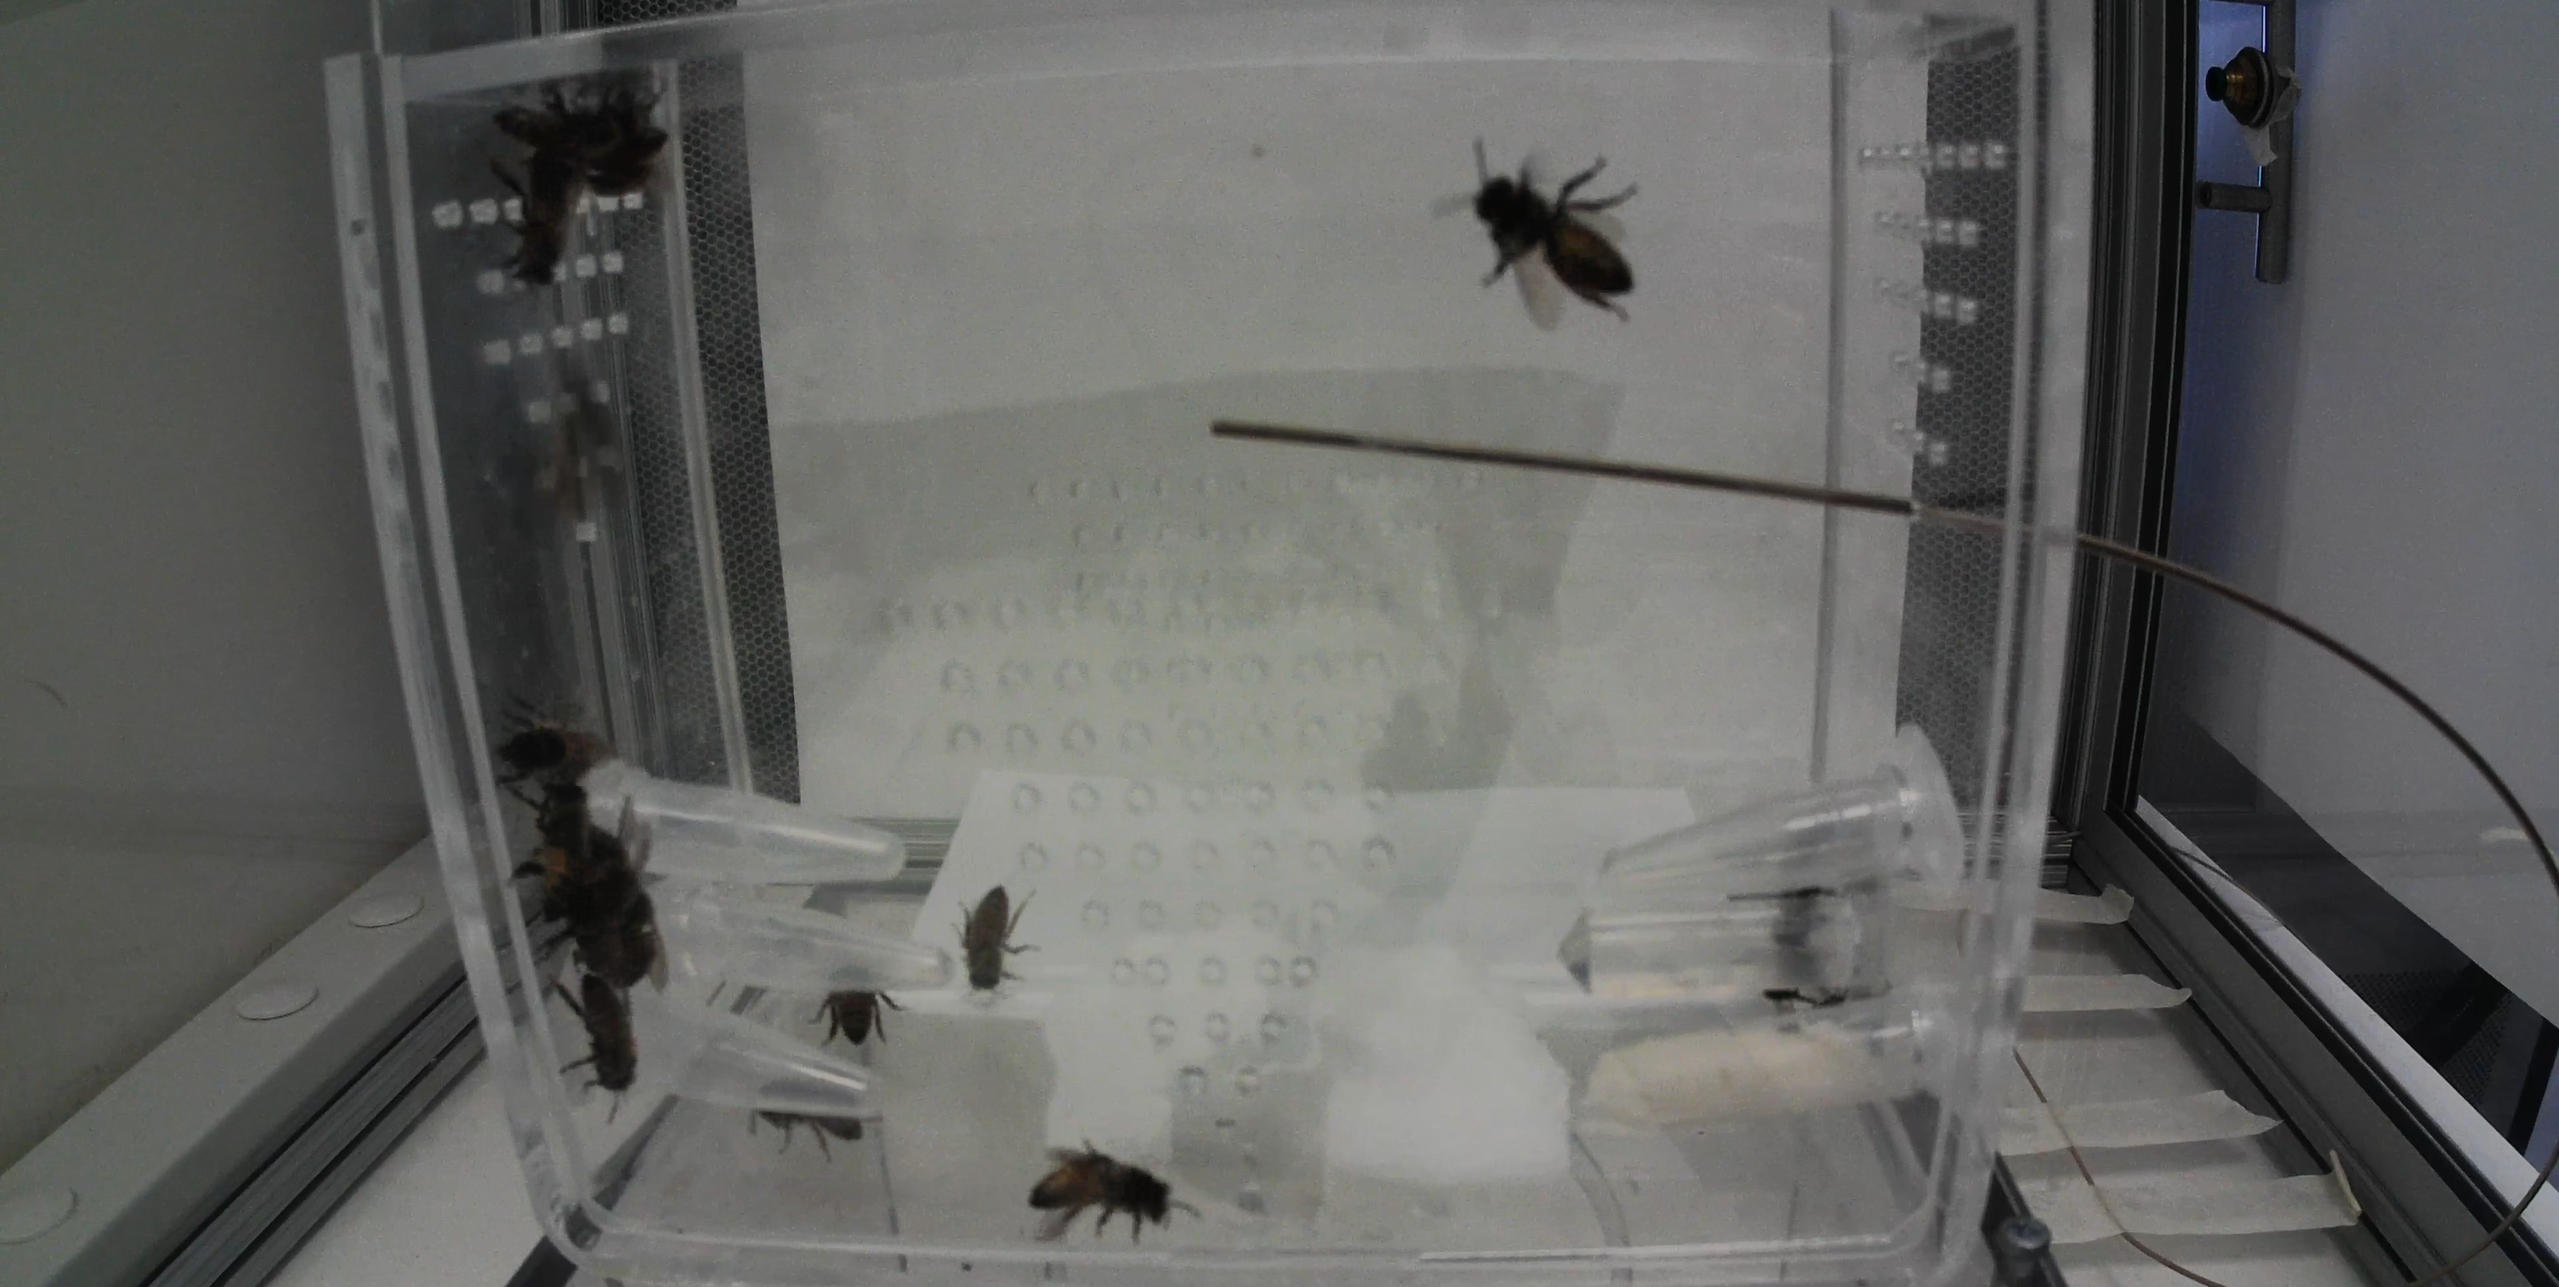

## MODALITÀ DI DEBUG E OTTIMIZZAZIONE DEL FLUSSO DI LAVORO
*Perché abbiamo usato il debug?*
L'elaborazione video (Computer Vision) è un processo estremamente "costoso" in
termini di tempo di calcolo. Processare 18 video che durano dai 10 ai 14 minuti richiedeva giorni.
Dunque bisognava attendere ore per verificare se una piccola modifica a un parametro
(es. cambiare l'Area Minima da 100 a 150) avesse avuto l'effetto desiderato.

Questa sezione serve a creare un "laboratorio rapido". Ci permette di lanciare
il codice e vedere i risultati in pochi minuti invece che in ore, facilitando
la calibrazione ("tuning") dei parametri suddetti.
1. `DEBUG_MODE`: È l'interruttore generale.
  - True: Siamo in fase di test.
  - False: Siamo pronti per l'analisi completa e definitiva di tutti i dati.
    
2. `DEBUG_MAX_FRAMES` = 1000:
   Invece di analizzare dai 10 ai 14 minuti di video, ne analizziamo solo 30 secondi (1000 frame).
   Questo è sufficiente per capire se il tracker sta funzionando bene o se perde le api,
   ma riduce il tempo di attesa del 98%.

3. `DEBUG_ONLY_FIRST_VIDEO` = True:
   Se l'algoritmo funziona bene sul primo video, probabilmente funzionerà anche sugli
   altri. Non ha senso processarli tutti e 18 durante la fase di test.

Combinando queste tre semplici variabili, abbiamo ottenuto una flessibilità totale per testare il sistema in scenari diversi.
- Solo il 1° video, solo per 1000 frame: ideale per vedere l'effetto immediato di una singola modifica ai filtri (es. correggere un riflesso improvviso).
- Solo il 1° video, ma per *tutti* i suoi frame (`MAX_FRAMES = None`): utile per verificare la tenuta del tracker sulla lunga distanza e assicurarsi che non ci fossero errori di memoria o derive del Background Subtractor.
- Tutti i 18 video, ma solo per i primi 1000 frame: un passaggio fondamentale per assicurarci che i parametri scelti non fossero "sovradattati" (*overfitted*) alle condizioni di luce del primo video, ma fossero robusti per l'intero dataset sperimentale.
- Spegnendo tutto (`DEBUG_MODE = False`), il sistema processa l'intero dataset.

In [ ]:
# ==========================================
# 1. CONFIGURAZIONE E DEBUG
# ==========================================

# --- PARAMETRI GLOBALI CONDIVISI ---
# Usiamo questi parametri nelle sezioni 4 e 7.

GLOBAL_MIN_HITS = 30      # Minima durata (frames) per considerare l'ape valida
GLOBAL_MAX_AGE  = 120     # Pazienza del tracker (frames) prima di perdere l'ape
GLOBAL_MIN_AREA = 300     # Dimensione minima (px) dell'oggetto
GLOBAL_MAX_AREA = 25000   # Dimensione massima (px) - Scarta gruppi di api

# --- IMPOSTAZIONI PER PROVE ---
DEBUG_MODE = False             # Metti False quando vuoi elaborare TUTTI i video completi
DEBUG_MAX_FRAMES = 1000        # Se DEBUG=True, analizza solo questi frame (es. 1000)
DEBUG_ONLY_FIRST_VIDEO = False # Se DEBUG=True, analizza solo il primo video trovato
# ----------------------------------------

# Percorso file ZIP
LOCAL_ZIP_PATH = None  # path to the video ZIP, e.g. r"C:\path\to\API VIDEO.zip"; if None, the script searches your Documents folder
# LOCAL_ZIP_PATH = None

# Cartella di output
out_dir = Path.cwd() / "dataset"
out_dir.mkdir(parents=True, exist_ok=True)
filename = "API VIDEO.zip"

## GESTIONE AUTOMATIZZATA DEL DATASET E DEI FILE

La seguente sezione del codice è progettata per rendere lo script portabile e robusto nella gestione dei dati di input. Invece di richiedere percorsi fissi (hardcoded), il sistema tenta di localizzare ed estrarre automaticamente i dati necessari.

Le funzionalità principali includono:

1.  **Ricerca Intelligente del File (`find_in_common_documents`)**:
    * Se il percorso del file ZIP non è specificato manualmente in `LOCAL_ZIP_PATH`, lo script cerca automaticamente il file `API VIDEO.zip` nelle cartelle *Documenti* standard dell'utente (sia su Windows che su sistemi Unix-based).
    * Questo permette di eseguire il notebook su computer diversi senza dover modificare il codice, purché il file sia nella cartella Documenti.

2.  **Estrazione Condizionale**:
    * Il codice verifica se la cartella di destinazione esiste già e se contiene file.
    * L'estrazione (`zipfile.extractall`) avviene solo se necessario, evitando di sovrascrivere i dati o perdere tempo a decomprimere l'archivio ad ogni esecuzione.

4.  **Indicizzazione dei Video**:
    * Scansiona la cartella estratta per identificare tutti i file video compatibili (estensioni `.mp4`, `.avi`, `.mov`).
    * Genera una lista `videos` contenente i percorsi completi, pronta per essere processata dal ciclo di analisi successivo.

In [ ]:
# ==========================================
# 2. GESTIONE FILE E DATASET
# ==========================================

def find_in_common_documents(name):
    candidates = [
        Path(os.path.expanduser("~/Documents")),
        Path(os.path.join(os.environ.get("USERPROFILE", ""), "Documents")),
        Path(os.path.expanduser("~")),
    ]
    checked = []
    for base in candidates:
        if not base.exists(): continue
        for root, dirs, files in os.walk(base):
            checked.append(root)
            if name in files:
                return Path(root) / name, checked
    return None, checked

# Trova ed estrai
if LOCAL_ZIP_PATH and Path(LOCAL_ZIP_PATH).exists():
    local_path = Path(LOCAL_ZIP_PATH)
else:
    found, checked = find_in_common_documents(filename)
    if found:
        local_path = found
    else:
        raise FileNotFoundError(f"File '{filename}' non trovato. Imposta LOCAL_ZIP_PATH.")

print(f"File trovato: {local_path}")
extract_dir_base = out_dir / "API_VIDEO"
extract_dir_base.mkdir(exist_ok=True)

if not extract_dir_base.exists() or not list(extract_dir_base.iterdir()):
    print("Estrazione in corso...")
    with zipfile.ZipFile(local_path, 'r') as zip_ref:
        zip_ref.extractall(extract_dir_base)
else:
    print("Cartella già estratta, salto estrazione.")

# Trova video
video_files_dir = extract_dir_base / "API VIDEO"
if not video_files_dir.exists():
    # Fallback se la struttura dello zip è diversa
    video_files_dir = extract_dir_base

videos = [f for f in os.listdir(video_files_dir) if f.lower().endswith((".mp4", ".avi", ".mov"))]
videos = [os.path.join(video_files_dir, v) for v in videos]
print(f"Video trovati: {len(videos)}")

File trovato: C:\Users\linac\OneDrive\Documenti\API VIDEO.zip
Cartella già estratta, salto estrazione.
Video trovati: 18


## CLASSI E FUNZIONI DI TRACKING
Questa sezione implementa i tre pilastri fondamenti del sistema di tracciamento multi-oggetto: **Rilevamento**, **Predizione** e **Associazione**.


### 1. RILEVAMENTO OGGETTI: BACKGROUND SUBTRACTION (MOG2)
----------------------------------------------------------------------------------
Il primo passo è distinguere le api (*foreground, primo piano*) dallo sfondo statico (*background*). Abbiamo utilizzato l'algoritmo **Mixture of Gaussians (MOG2)** per la sottrazione dello sfondo. Esso rileva oggetti in movimento in un flusso video, adattandosi ai cambiamenti di illuminazione.

A differenza della semplice sottrazione di frame consecutivi (MOG), MOG2 modella ogni pixel come una mistura di distribuzioni gaussiane ($K$ distribuzioni). La probabilità che un pixel $X_t$ appartenga allo sfondo è data da:

$$P(X_t) = \sum_{i=1}^{K} \omega_{i,t} \cdot \eta(X_t, \mu_{i,t}, \Sigma_{i,t})$$

dove $\omega$ è il peso, $\mu$ la media e $\Sigma$ la covarianza. Questo permette al sistema di adattarsi a cambiamenti graduali di luce, considerando come "sfondo" tutto ciò che rimane stabile per un certo periodo di tempo. In altre parole, quando arriva un nuovo frame, MOG2 confronta il colore di ogni pixel con il modello statistico costruito nei frame precedenti.
- Se il colore del pixel corrisponde ad una delle gaussiane probabili, il pixel viene classificato come sfondo.
- Se il colore del pixel non corrisponde a nessuna gaussiana di sfondo, viene considerato parte di un oggetto in movimento.

**Aggiornamento adattivo**: il punto di forza di MOG2 è che aggiorna continuamente il modello statistico per ogni pixel. Il che significa che si adatta ai cambiamenti lenti della scena (come i cambi di luce suddetti) e apprende, ad esempio, che un oggetto può diventare parte del background dopo un po' di tempo. MOG2 riconosce anche le ombre.

Parametri principali per il MOG2:
- `history` è il numero di frame precedenti usati per calcolare il modello di sfondo.
- `varThreshold` è la soglia che definisce quanto un pixel debba essere diverso dallo sfondo per essere considerato movimento.
- `detectShadows` (booleano) se True, rileva le ombre (riduce la precisione del movimento ma pulisce la scena).

**Pulizia del segnale**: nel codice, applichiamo successivamente un'operazione morfologica di **Apertura** (Erosione + Dilatazione) per rimuovere il rumore granulare.

L'**erosione** serve principalmente a eliminare il rumore di fondo. Funziona "erodendo" i bordi delle aree bianche: se un pixel bianco non è circondato da una massa solida di altri pixel bianchi, viene trasformato in nero. In pratica, elimina tutti quei piccoli puntini bianchi che non sono veri oggetti in movimento, ma semplici interferenze video.

La **dilatazione** svolge la funzione opposta: ispessisce e ricompatta. Espande i confini delle aree bianche rimaste dopo la pulizia, facendo sì che i pixel bianchi "conquistino" lo spazio nero circostante. In pratica, serve a chiudere i piccoli buchi interni all'oggetto (causati, ad esempio, da una maglietta dello stesso colore dello sfondo) e a ricongiungere parti vicine che dovrebbero formare un'unica sagoma.

### 2. PREDIZIONE E STIMA: IL FILTRO DI KALMAN
----------------------------------------------------------------------------------
Una volta rilevato un oggetto, è necessario prevedere dove sarà nel frame successivo. Il **Filtro di Kalman** è uno stimatore ricorsivo ottimale per sistemi lineari affetti da rumore gaussiano.

Nel nostro codice, ogni ape è un'istanza della classe `Track` che possiede un filtro di Kalman associato. Lo stato del sistema $\mathbf{x}$ è definito da un vettore a 4 dimensioni:

$$\mathbf{x} = [x, v_x, y, v_y]^T$$

dove $(x,y)$ è la posizione e $(v_x, v_y)$ la velocità. Il filtro opera ciclicamente in due fasi:
1.  **Predizione:** Stima la posizione al tempo $k$ basandosi sullo stato al tempo $k-1$ (sfruttando un modello fisico a velocità costante).
2.  **Aggiornamento:** Corregge la stima utilizzando la misura reale fornita dal rilevatore visivo (MOG2).

La stima finale è una media ponderata tra la previsione e la misurazione.

Questo permette di "mantenere viva" la traccia di un'ape anche se per qualche frame la rilevazione visiva fallisce (es. riflesso o occlusione momentanea).

### 3. ASSOCIAZIONE DATI: ALGORITMO UNGHERESE
----------------------------------------------------------------------------------
Ad ogni frame, otteniamo $N$ rilevazioni dal MOG2 e abbiamo $M$ tracce attive dal Kalman. Dobbiamo capire quale rilevazione corrisponde a quale traccia.

Abbiamo utilizzato l'**Hungarian Algorithm** (o *Linear Sum Assignment*, implementato in `scipy`) basato su una matrice di costo, necessario proprio a risolvere problemi di assegnazione.
* **Matrice dei Costi:** Ogni cella $(i, j)$ rappresenta la *distanza euclidea* tra la posizione predetta dal Kalman (Traccia $i$) e la posizione rilevata dal MOG2 (Blob $j$).
* **Ottimizzazione:** L'algoritmo minimizza il costo globale di assegnazione, garantendo l'accoppiamento più probabile.
* **Gating:** Le associazioni che superano una distanza massima (`max_dist`) vengono scartate per evitare errori fisicamente impossibili.

In [ ]:
# ==============================================================================
# 3. CLASSI E FUNZIONI DI TRACKING
# ==============================================================================

# --- Background Subtractor Globale ---
# Inizializza l'algoritmo MOG2 (Mixture of Gaussians) per la sottrazione dello sfondo.
# - history=500: Il modello "impara" lo sfondo basandosi sugli ultimi 500 frame.
# - varThreshold=25: Soglia di varianza (distanza di Mahalanobis). Valori più bassi rilevano più movimento (più sensibile).
# - detectShadows=False: Disabilitato perché le ombre possono essere scambiate per oggetti.
fgbg = cv2.createBackgroundSubtractorMOG2(history=500, varThreshold=25, detectShadows=False)

def detect_blobs(frame, min_area=50, max_area=None): # Questa funzione prende in input un frame, lo converte in scala di grigi e applica la maschera MOG2
    """
    Rileva oggetti in movimento (blobs) nel frame corrente usando Background Subtraction.

    Args:
        frame (numpy.ndarray): L'immagine del frame corrente.
        min_area (int): Area minima in pixel per considerare un contorno valido (filtro rumore).
        max_area (int, optional): Area massima in pixel. Se None, non c'è limite superiore.

    Returns:
        tuple:
            - detections (list): Lista di tuple (centro_x, centro_y, area, (x, y, w, h)).
            - found_areas (list): Lista delle aree grezze trovate (utile per debug/statistiche).
    """
    # 1. Pre-processing: Converti in scala di grigi
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    # 2. Background Subtraction: Ottieni la maschera binaria (bianco=movimento, nero=sfondo)
    fg = fgbg.apply(gray)

    # 3. Pulizia Morfologica: 'Opening' (Erosione seguita da Dilatazione)
    # Serve a rimuovere il rumore "sale e pepe" (piccoli puntini bianchi isolati).
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3,3))
    fg = cv2.morphologyEx(fg, cv2.MORPH_OPEN, kernel, iterations=1)

    # 4. Estrazione Contorni
    contours, _ = cv2.findContours(fg, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    detections = []
    found_areas = [] # Lista per salvare le aree di questo frame per analisi statistiche

    for c in contours:
        area = cv2.contourArea(c)

        # --- Sezione Filtri Dimensionali ---
        # Scarta oggetti troppo piccoli (probabile rumore)
        if area < min_area: continue
        # Scarta oggetti troppo grandi (probabili agglomerati o artefatti, se max_area è impostato)
        if max_area and area > max_area: continue

        # Se passa i filtri, salviamo l'area
        found_areas.append(area)

        # Calcolo Bounding Box e Centroide
        x, y, w, h = cv2.boundingRect(c)
        cx = x + w/2
        cy = y + h/2

        # Salviamo la detection formattata
        detections.append((cx, cy, area, (x,y,w,h)))

    # Restituiamo sia le detection per il tracker, sia le aree per la statistica
    return detections, found_areas

class Track:
    """
    Rappresenta un singolo oggetto tracciato nel tempo utilizzando un Filtro di Kalman.
    Stima lo stato (posizione e velocità) per gestire occlusioni e rumore.
    """
    def __init__(self, init_pos, track_id, dt=1.0):
        """
        Inizializza il tracker per una nuova ape.

        Args:
            init_pos (tuple): Coordinate iniziali (x, y).
            track_id (int): Identificativo univoco della traccia.
            dt (float): Passo temporale tra i frame (default 1.0, o 1/fps).
        """
        # Inizializza filtro di Kalman:
        # dim_x=4 -> Stato interno: [pos_x, vel_x, pos_y, vel_y]
        # dim_z=2 -> Misura osservata: [pos_x, pos_y]
        self.kf = KalmanFilter(dim_x=4, dim_z=2)

        # Matrice di Transizione di Stato (F)
        # Definisce il modello fisico: Pos_t = Pos_t-1 + Vel_t-1 * dt
        self.kf.F = np.array([[1, dt, 0, 0],
                              [0, 1, 0, 0],
                              [0, 0, 1, dt],
                              [0, 0, 0, 1]])

        # Matrice di Misura (H)
        # Mappa lo stato interno alle misure osservate (noi misuriamo solo posizione, non velocità)
        self.kf.H = np.array([[1, 0, 0, 0],
                              [0, 0, 1, 0]])

        # Matrice di Covarianza dell'Errore (P)
        # Inizializzata alta (500) perché all'inizio siamo incerti sulla stima
        self.kf.P *= 500.

        # Matrice di Rumore di Misura (R)
        # Quanto ci fidiamo del rilevatore visivo? (5.0 = fiducia media)
        self.kf.R = np.eye(2) * 5.

        # Matrice di Rumore di Processo (Q)
        # Quanto l'oggetto può deviare dal modello a velocità costante (accelerazioni, cambi direzione)
        self.kf.Q = np.eye(4) * 1.0

        # Stato Iniziale (x)
        self.kf.x = np.array([init_pos[0], 0., init_pos[1], 0.]).reshape(-1,1)

        self.id = track_id
        self.age = 1               # Quanti frame è durata la traccia
        self.time_since_update = 0 # Da quanti frame non vediamo l'oggetto (per la cancellazione)
        self.history = []          # Storico delle posizioni

    def predict(self):
        """
        Fase di Predizione del Kalman Filter.
        Stima dove sarà l'oggetto nel prossimo frame basandosi sulla velocità attuale.
        """
        self.kf.predict()
        self.age += 1
        self.time_since_update += 1
        self.history.append(self.kf.x.copy())
        return self.kf.x.copy()

    def update(self, measurement):
        """
        Fase di Correzione del Kalman Filter.
        Aggiorna la stima usando la posizione reale rilevata nel frame corrente.
        """
        self.kf.update(np.array(measurement).reshape(2,1))
        self.time_since_update = 0 # Reset contatore, oggetto visto!

    def get_state(self):
        """
        Restituisce lo stato corrente stimato (posizione x, y) e la matrice di covarianza.
        """
        # Nota: .item() estrae il valore scalare nativo Python dal numpy array/matrix
        # questo è fondamentale per evitare Warning o errori di serializzazione futuri.
        return float(self.kf.x[0].item()), float(self.kf.x[2].item()), self.kf.P.copy()

def associate_detections_to_tracks(detections, tracks, max_dist=50):
    """
    Associa le nuove rilevazioni (blobs) alle tracce esistenti (Kalman Filters)
    utilizzando l'Algoritmo Ungherese (Hungarian Algorithm / Munkres).

    Args:
        detections (list): Lista delle detection dal frame corrente.
        tracks (list): Lista degli oggetti Track attivi.
        max_dist (int): Distanza massima (in pixel) per considerare valida un'associazione.

    Returns:
        tuple: matches (pairs), unmatched_detections, unmatched_tracks
    """
    # Caso base: Nessuna traccia esistente -> Tutte le detection sono nuove
    if len(tracks) == 0:
        return [], list(range(len(detections))), []

    # 1. Costruzione Matrice dei Costi (D)
    # Calcola la distanza Euclidea tra ogni traccia (predetta) e ogni detection
    D = np.zeros((len(tracks), len(detections)))
    for t, tr in enumerate(tracks):
        tx, ty, _ = tr.get_state()
        for d, det in enumerate(detections):
            # det[0], det[1] sono cx, cy
            D[t, d] = np.hypot(det[0] - tx, det[1] - ty)

    # 2. Ottimizzazione (Algoritmo Ungherese)
    # Trova l'assegnazione che minimizza la somma totale delle distanze
    row_ind, col_ind = linear_sum_assignment(D)

    matches = []
    unmatched_tracks = []
    unmatched_dets = []

    # 3. Filtraggio delle associazioni
    matched_indices = set()
    for r, c in zip(row_ind, col_ind):
        # Se la distanza è troppo grande, è un falso positivo o un'altra ape
        if D[r, c] > max_dist:
            unmatched_tracks.append(r)
            unmatched_dets.append(c)
        else:
            matches.append((r, c))
            matched_indices.add(c)

    # 4. Identificazione dei residui
    # Tracce che non hanno trovato un match nell'ottimizzazione
    unmatched_tracks.extend([t for t in range(len(tracks)) if t not in row_ind])
    # Detection che non sono state assegnate a nessuna traccia
    unmatched_dets.extend([d for d in range(len(detections)) if d not in matched_indices])

    return matches, unmatched_dets, unmatched_tracks

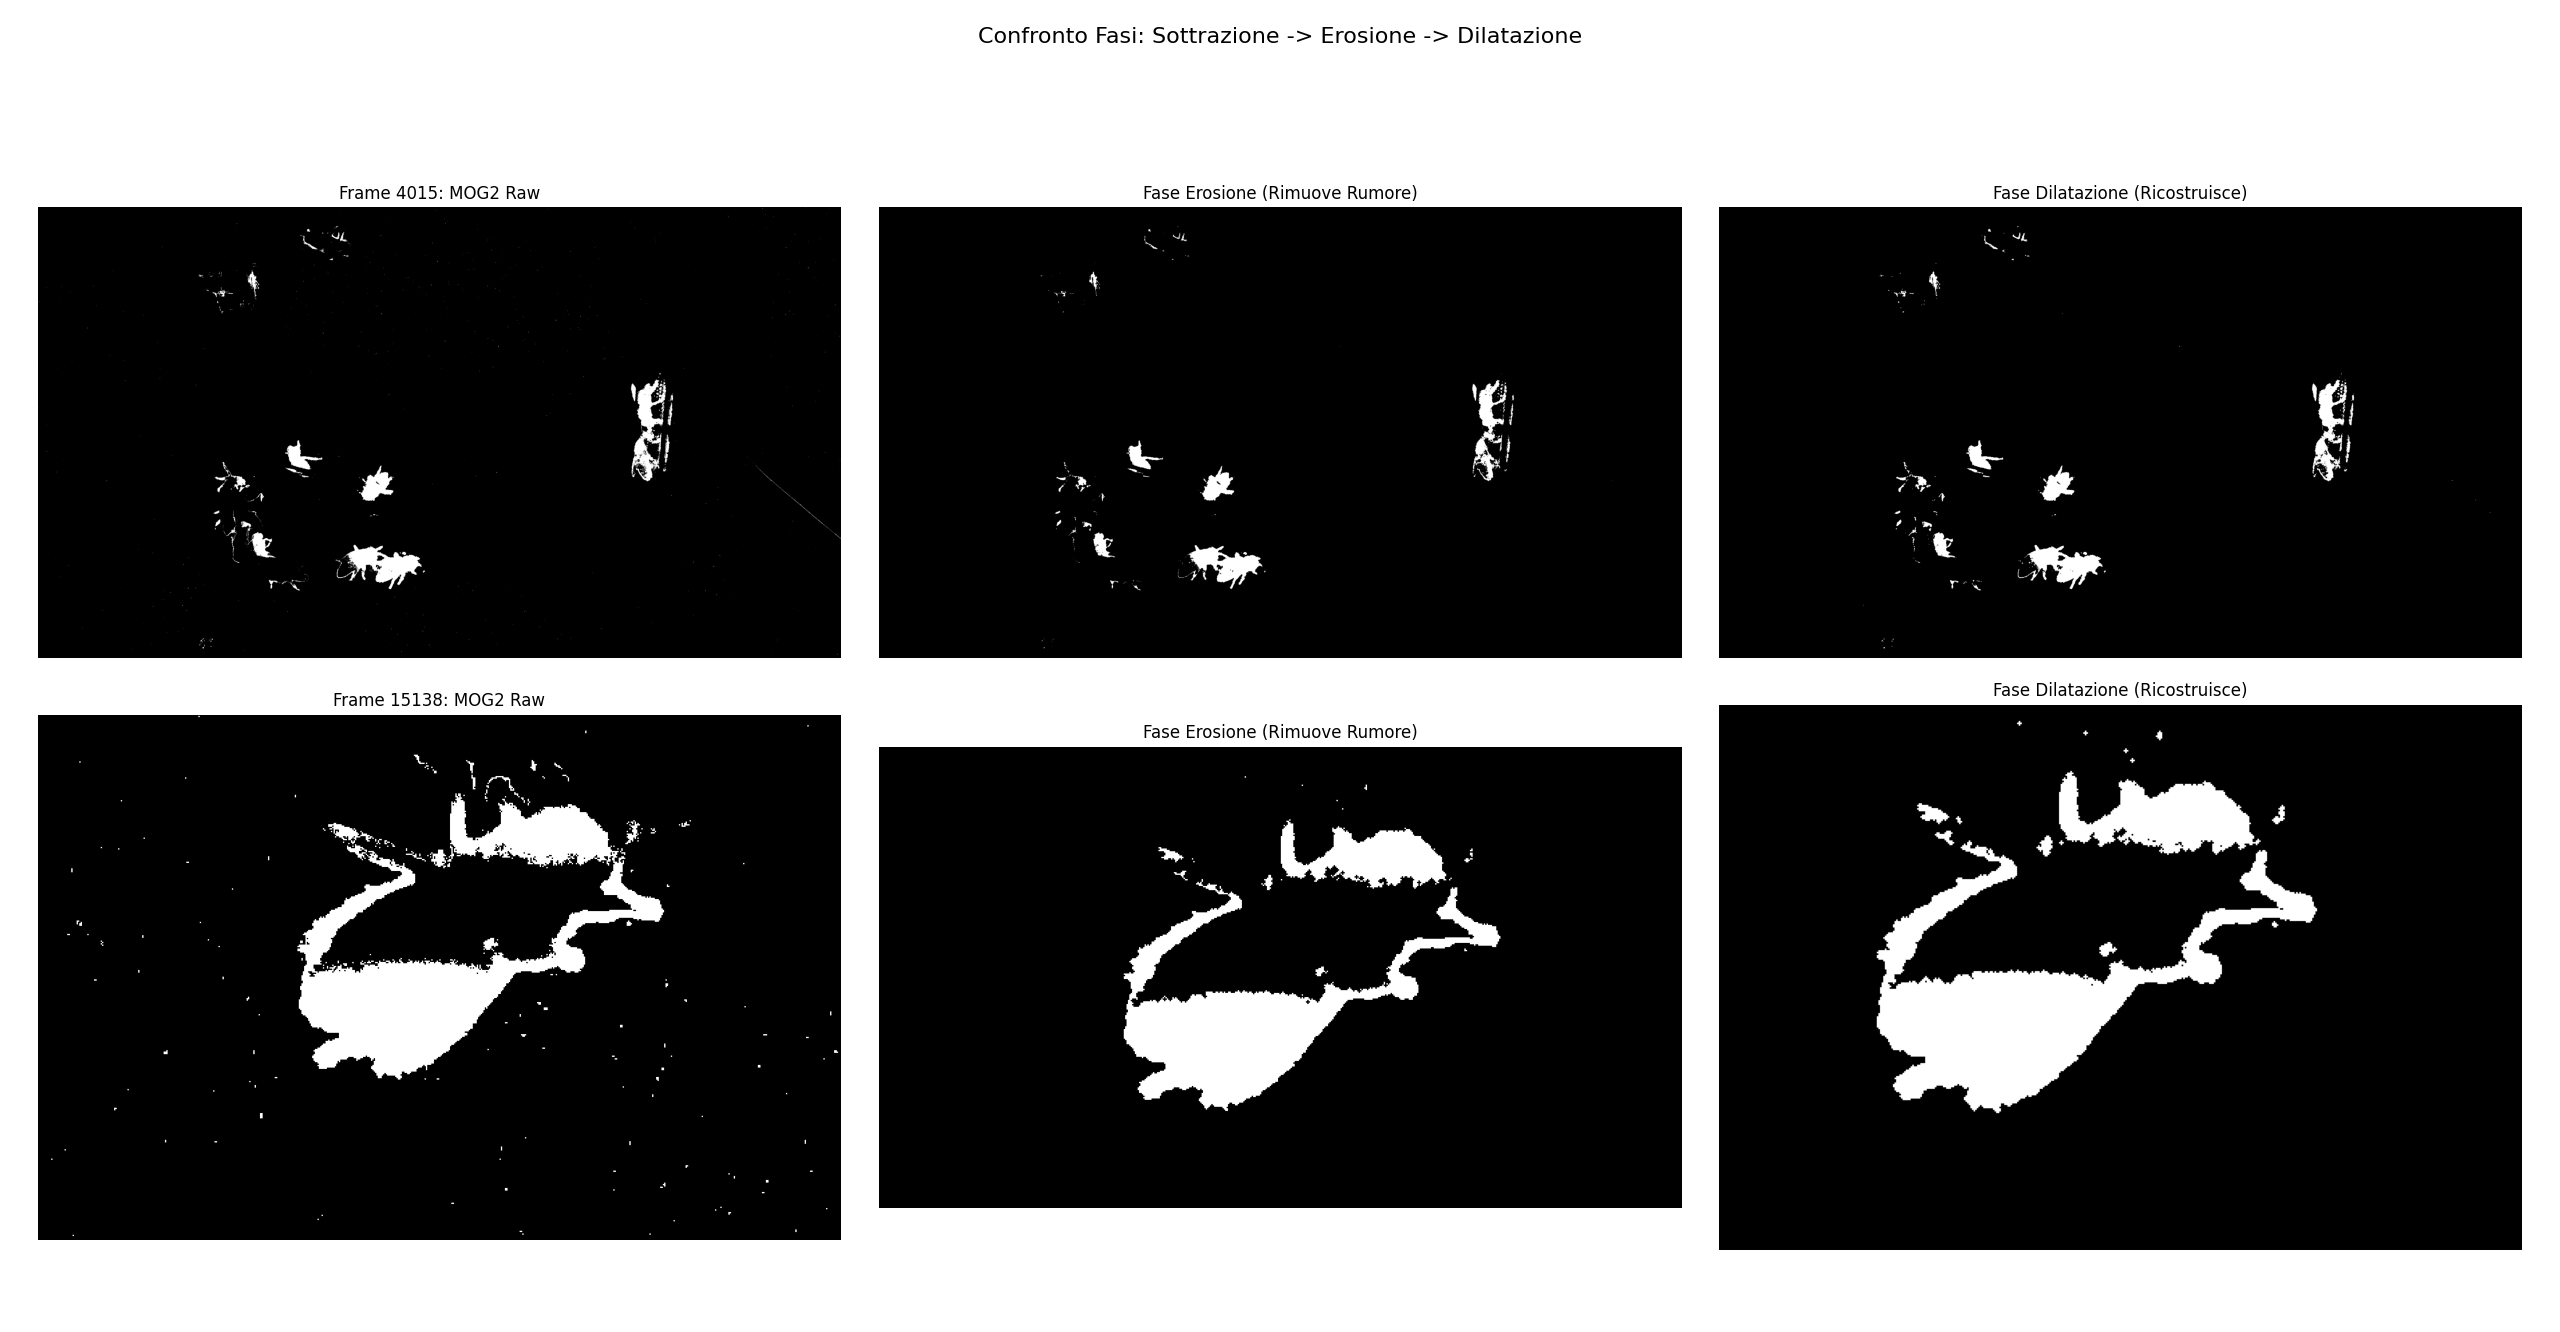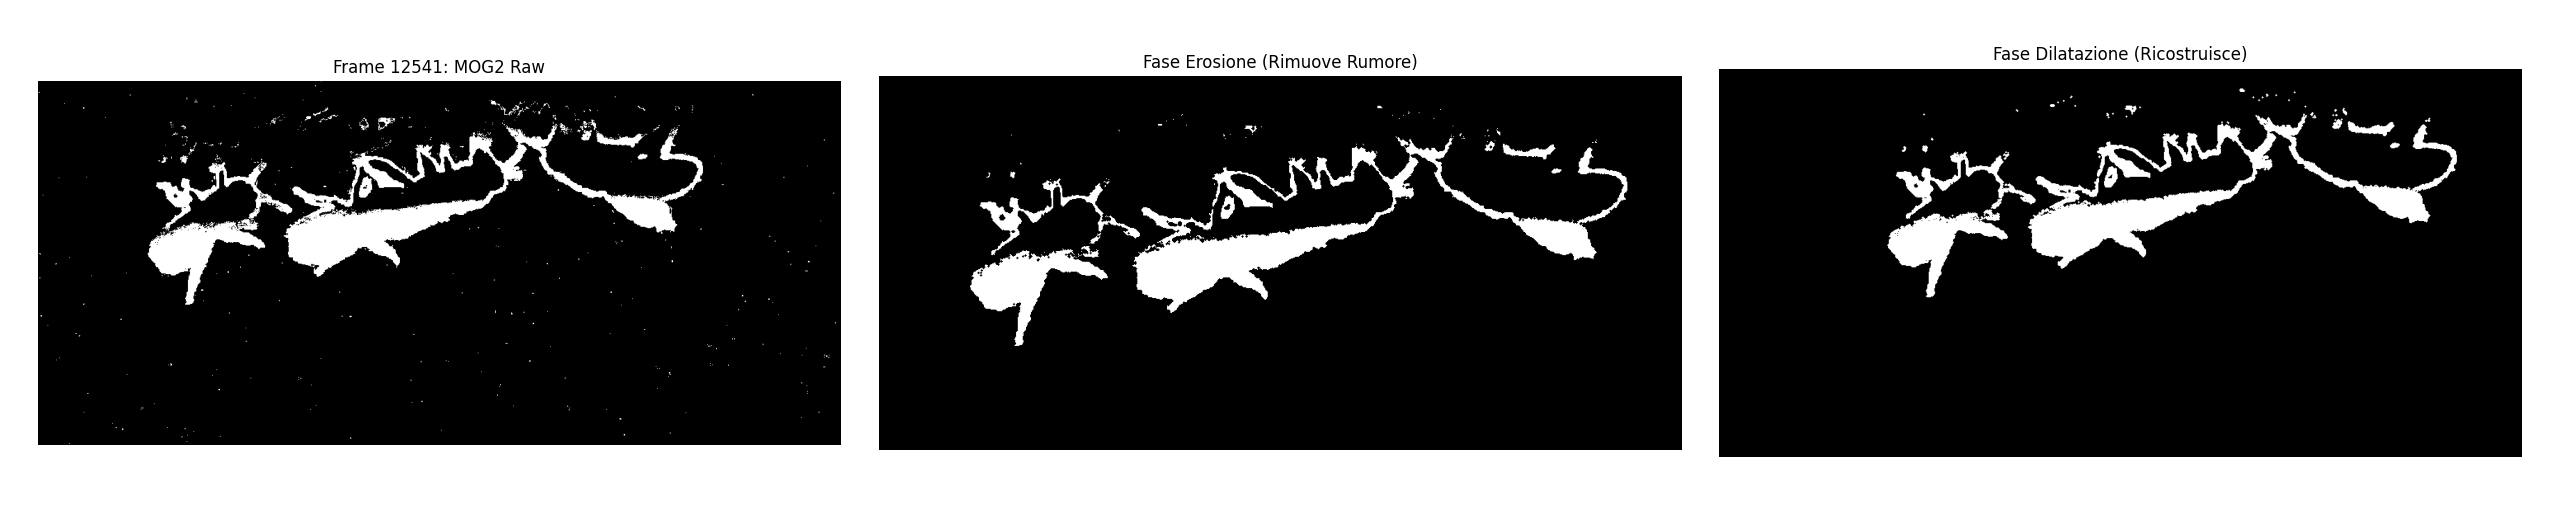

## PROCESSO VIDEO: PIPELINE DI TRACCIAMENTO E FILTRAGGIO

Questa sezione definisce il "motore" principale dell'applicazione (`process_video`). Qui vengono integrati i moduli di rilevamento e tracciamento definiti in precedenza per analizzare il flusso video frame per frame.

### 1. CONFIGURAZIONE DEL BACKGROUND SUBTRACTOR (MOG2)
Prima di avviare il processo, inizializziamo l'algoritmo di sottrazione dello sfondo con parametri specifici per ridurre il rumore ambientale:

* **`history=500`**: Il modello statistico dello sfondo viene costruito osservando gli ultimi 500 frame.
* **`varThreshold=50`** (Default è 16): Abbiamo aumentato significativamente questa soglia.
    * *Perché?* Una soglia più alta rende il rilevatore **meno sensibile**. Questo è fondamentale per ignorare le piccole variazioni di luce, i riflessi sulle pareti di plastica e il rumore del sensore, focalizzandosi solo sugli oggetti con un contrasto netto (le api).
* **`detectShadows=False`**: Disabilitato per evitare che le ombre proiettate dalle api vengano tracciate come oggetti a sé stanti o deformino i contorni dell'insetto.



### 2. LA FUNZIONE `process_video`
Questa funzione orchestra l'intero ciclo di vita del tracciamento:

1.  **Acquisizione e Rilevamento:** Per ogni frame, estrae i "blob" (api potenziali) filtrandoli per dimensione (`GLOBAL_MIN_AREA`, `GLOBAL_MAX_AREA`).
2.  **Associazione Dati:** Utilizza l'algoritmo Ungherese per collegare i nuovi blob alle tracce esistenti.
3.  **Aggiornamento Kalman:**
    * Le tracce associate vengono corrette (*Update*) con la nuova posizione misurata.
    * Le tracce non associate vengono predette (*Predict*) basandosi sulla velocità precedente (gestione occlusioni).
4.  **Gestione Vita Traccia:**
    * **Nascita:** I blob non associati generano nuove tracce (`Track`).
    * **Morte:** Le tracce che non ricevono aggiornamenti per un tempo superiore a `GLOBAL_MAX_AGE` vengono eliminate.
5.  **Post-Processing e Pulizia:**
    * Raccoglie statistiche sulle dimensioni (Min/Max/Avg) per facilitare il tuning dei parametri.
    * **Filtro Finale:** Prima di salvare il CSV, scarta tutte le tracce che hanno avuto una vita inferiore a `GLOBAL_MIN_HITS`. Questo elimina definitivamente i "falsi positivi" (rumore temporaneo) che potrebbero essere sfuggiti ai filtri precedenti.

In [ ]:
# ==========================================
# 4. PROCESSO VIDEO CON FILTRI ANTI-RUMORE
# ==========================================

# --- Inizializzazione Background Subtractor ---
# Utilizziamo MOG2 con parametri tarati per ridurre i falsi positivi.
# varThreshold=50: Soglia alta per ignorare piccoli cambiamenti di luce/riflessi.
# detectShadows=False: Le ombre non sono api, disabilitiamo per performance e precisione.
fgbg = cv2.createBackgroundSubtractorMOG2(history=500, varThreshold=50, detectShadows=False)

def process_video(path, output_csv, max_frames=None):
    """
    Elabora un file video per tracciare le api, filtrare il rumore e salvare le traiettorie.

    Fasi principali:
    1. Lettura frame-per-frame.
    2. Rilevamento oggetti (blob detection).
    3. Tracking (Kalman Filter + Hungarian Algorithm).
    4. Raccolta statistiche dimensionali.
    5. Filtraggio finale delle tracce brevi (rumore).

    Args:
        path (str): Percorso del file video di input.
        output_csv (str): Percorso dove salvare il file CSV delle traiettorie.
        max_frames (int, optional): Numero massimo di frame da analizzare (per debug).

    Returns:
        pandas.DataFrame: DataFrame contenente tutte le traiettorie valide.
    """
    cap = cv2.VideoCapture(str(path))
    fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
    total_frames_video = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    tracks = []          # Lista degli oggetti Track attivi
    next_id = 0          # Contatore per assegnare ID univoci
    trajectories = {}    # Dizionario per memorizzare la storia completa {id: [dati]}
    frame_idx = 0

    # Lista per accumulare TUTTE le aree valide trovate (per analisi statistica post-processo)
    all_video_areas = []

    print(f"\n[INFO] Inizio elaborazione: {os.path.basename(path)}")
    print(f"       Filtri attivi: Min Area={GLOBAL_MIN_AREA}px, Max Area={GLOBAL_MAX_AREA}px")

    while True:
        ret, frame = cap.read()
        if not ret: break

        # Monitoraggio avanzamento
        if frame_idx % 100 == 0:
            # Conta quanti track sono stati aggiornati in questo preciso frame (visti ora)
            active_tracks = len([t for t in tracks if t.time_since_update == 0])
            print(f"    Frame {frame_idx}/{total_frames_video} - Tracks attivi: {active_tracks}", end='\r')

        # -----------------------------------------------------------
        # 1. RILEVAMENTO
        # Ottiene i centri degli oggetti e le loro aree
        # -----------------------------------------------------------
        detections, frame_areas = detect_blobs(frame, min_area=GLOBAL_MIN_AREA, max_area=GLOBAL_MAX_AREA)

        # Accumuliamo le aree trovate in questo frame nella lista globale
        all_video_areas.extend(frame_areas)

        # -----------------------------------------------------------
        # 2. ASSOCIAZIONE E UPDATE
        # Collega le detection ai track esistenti
        # -----------------------------------------------------------
        matches, unmatched_dets, unmatched_tracks = associate_detections_to_tracks(detections, tracks, max_dist=100)

        # A. Predizione per TUTTI i track (anche quelli non visti)
        for tr in tracks: tr.predict()

        # B. Update per i track che hanno trovato un match (Correction)
        for tr_idx, det_idx in matches:
            cx, cy, _, _ = detections[det_idx]
            tracks[tr_idx].update((cx, cy))

            # Salvataggio dati nello storico
            tid = tracks[tr_idx].id
            x, y, _ = tracks[tr_idx].get_state()
            trajectories.setdefault(tid, []).append((frame_idx, frame_idx/fps, x, y))

        # C. Creazione nuovi track per detection non associate (Nuove api)
        for det_idx in unmatched_dets:
            cx, cy, _, _ = detections[det_idx]
            new_track = Track((cx, cy), next_id, dt=1.0/fps)
            tracks.append(new_track)
            trajectories.setdefault(next_id, []).append((frame_idx, frame_idx/fps, float(cx), float(cy)))
            next_id += 1

        # -----------------------------------------------------------
        # 3. GESTIONE VITA TRACK
        # Rimuove i track che non vengono visti da troppo tempo (> MAX_AGE)
        # -----------------------------------------------------------
        tracks = [tr for tr in tracks if tr.time_since_update < GLOBAL_MAX_AGE]

        frame_idx += 1
        if max_frames and frame_idx >= max_frames: break

    cap.release()

    # -----------------------------------------------------------
    # 4. ANALISI STATISTICA E PULIZIA FINALE
    # -----------------------------------------------------------

    # Stampa statistiche sulle dimensioni (utile per tuning GLOBAL_MIN_AREA)
    if all_video_areas:
        overall_min = min(all_video_areas)
        overall_max = max(all_video_areas)
        overall_avg = sum(all_video_areas) / len(all_video_areas)
        print(f"\n    [STATISTICHE DIMENSIONI API]")
        print(f"    -> Ape più piccola rilevata: {int(overall_min)} px")
        print(f"    -> Ape più grande rilevata:  {int(overall_max)} px")
        print(f"    -> Dimensione media:         {int(overall_avg)} px")
    else:
        print("\n    [!] Nessuna ape rilevata con i filtri attuali.")

    # Salvataggio su CSV filtrando le tracce "rumorose" (troppo brevi)
    print(f"    Pulizia tracce brevi (< {GLOBAL_MIN_HITS} frames)...")
    final_rows = []
    valid_count = 0

    for tid, seq in trajectories.items():
        # Filtro Min Hits: Se la traccia è durata meno di X frame, è considerata rumore
        if len(seq) >= GLOBAL_MIN_HITS:
            valid_count += 1
            for (f_idx, t_sec, x, y) in seq:
                final_rows.append({'track_id': tid, 'frame': f_idx, 't': t_sec, 'x': x, 'y': y})

    df = pd.DataFrame(final_rows)
    df.to_csv(output_csv, index=False)
    return df

## ESECUZIONE PRINCIPALE: ANALISI BATCH E STATISTICHE AVANZATE

Questa sezione rappresenta il ciclo principale dello script. Qui vengono processati sequenzialmente tutti i video, vengono aggregate le tracce e calcolate le metriche definitive sulla popolazione.

### 1. IL CAMBIO PARADIGMA: DAL "TOTALE" ALLA "MEDIA"
Una delle sfide principali nel tracciamento automatico è la frammentazione: se un'ape si nasconde sotto un'altra (occlusione) o rimane completamente immobile a lungo, il sistema smette di tracciarla. Quando questa si muove di nuovo, il tracker non la riconosce e le assegna un nuovo ID. In un video lungo, questo fenomeno si ripete centinaia di volte. Se ci sono 20 api reali in una scatola, l'algoritmo a fine video potrebbe aver generato 150 ID univoci. Valutare la popolazione sul conteggio "cumulativo" porta a una sovrastima enorme.

Per ottenere un dato biologicamente rilevante, calcoliamo la **distribuzione temporale** delle api presenti frame per frame, cioè il codice analizza quante tracce sono attive simultaneamente in un singolo istante.

* **Media (`mean`):** Calcola il numero medio di tracce attive istante per istante. È la metrica più robusta per rispondere alla domanda *"Quante api ci sono mediamente nella scatola in questo momento?"*.
* **5° e 95° Percentile:** In un video possono verificarsi picchi anomali (es. un forte riflesso improvviso genera 10 tracce false per un secondo) o crolli anomali (es. la telecamera perde il fuoco). Usare la deviazione standard o i semplici valori minimi e massimi sarebbe fuorviante. Il 5° e il 95° percentile tagliano via quel 5% di dati anomali (i "rumori"), offrendo un **intervallo di confidenza** estremamente robusto. Significa poter affermare: *"Per il 90% del tempo, in questa scatola erano visibili tra X e Y api"*.

### 2. GESTIONE GLOBAL ID (DATASET UNIFICATO)
Poiché stiamo unendo dati provenienti da video diversi (es. *Video_1* e *Video_2*), esiste il rischio di collisione degli ID (l'Ape #1 del primo video non è l'Ape #1 del secondo).

Per risolvere questo problema, implementiamo un meccanismo di **ID Offset**:
1.  Al termine di ogni video, memorizziamo il valore massimo dell'ID raggiunto.
2.  Sommiamo questo valore a tutti gli ID del video successivo.
3.  Questo garantisce che nel file finale `tracks_all_videos.csv`, ogni singola traccia abbia un identificativo univoco globale, permettendo analisi aggregate corrette.

In [ ]:
# ==========================================
# 5. ESECUZIONE PRINCIPALE & CONTEGGIO API
# ==========================================

all_tracks = [] # Lista contenitore per tutti i dataframe dei singoli video

# Filtro Debug: Se attivo, processa solo il primo video per risparmiare tempo
videos_to_process = videos[:1] if (DEBUG_MODE and DEBUG_ONLY_FIRST_VIDEO) else videos

# Contatore per ID univoci globali
# Serve a evitare che l'ID 1 del Video A si confonda con l'ID 1 del Video B
id_offset = 0

# Liste per salvare le metriche statistiche da graficare
video_numbers = []
avg_counts = []   # Media temporale delle api presenti
pct95_counts = [] # 95° percentile (Picco robusto)
pct05_counts = [] # 5° percentile (Minimo robusto/Base popolazione)

print("\n--- INIZIO ANALISI DETTAGLIATA ---")

for i, video_path in enumerate(videos_to_process):
    video_name = os.path.splitext(os.path.basename(video_path))[0]
    csv_out = out_dir / f"tracks_{video_name}.csv"

    # Imposta il limite di frame se siamo in debug mode
    limit = DEBUG_MAX_FRAMES if DEBUG_MODE else None

    # --- ESECUZIONE PIPELINE DI TRACKING ---
    # process_video restituisce il dataframe delle tracce
    df_video = process_video(video_path, csv_out, max_frames=limit)

    # --- CALCOLO STATISTICHE POPOLAZIONE (Frame-by-Frame) ---
    if not df_video.empty:
        # Raggruppa per 'frame' e conta gli ID unici presenti in quell'istante
        # active_per_frame è una Serie temporale: es. {Frame 1: 15 api, Frame 2: 16 api...}
        active_per_frame = df_video.groupby('frame')['track_id'].count()

        # 1. Media Temporale: La stima più fedele della popolazione media
        avg_active = active_per_frame.mean()

        # 2. Percentili: Per capire la varianza (minimi e massimi robusti ai falsi positivi/negativi)
        pct95_active = active_per_frame.quantile(0.95)
        pct05_active = active_per_frame.quantile(0.05)

        n_bees = df_video['track_id'].nunique() # Solo info testuale (spesso sovrastimata)
    else:
        # Caso di video vuoto o nessun rilevamento
        avg_active = 0
        pct95_active = 0
        pct05_active = 0
        n_bees = 0

    # Salvataggio dati per i grafici finali
    video_idx = i + 1  # Indice video base-1 (1, 2, 3...)
    video_numbers.append(video_idx)
    avg_counts.append(avg_active)
    pct95_counts.append(pct95_active)
    pct05_counts.append(pct05_active)

    print(f"> Video {video_idx} ({video_name}): Media={avg_active:.2f}, 5°Pct={pct05_active:.2f}, 95°Pct={pct95_active:.2f}")

    # --- UNIONE DATASET E GESTIONE ID GLOBALI ---
    if not df_video.empty:
        # Aggiungi l'offset agli ID del video corrente per renderli univoci nel dataset globale
        df_video['track_id'] = df_video['track_id'] + id_offset

        # Aggiorna l'offset per il prossimo video (Max ID corrente + 1)
        max_id_in_video = df_video['track_id'].max()
        id_offset = max_id_in_video + 1

        # Aggiungi colonna nome video e accoda al dataset globale
        df_video['video'] = video_name
        all_tracks.append(df_video)

# Creazione e salvataggio del Dataset Unificato
if all_tracks:
    df_all = pd.concat(all_tracks, ignore_index=True)
    final_csv = out_dir / "tracks_all_videos.csv"
    df_all.to_csv(final_csv, index=False)
    print(f"\nCOMPLETATO. Dataset unificato salvato in: {final_csv}")
    print(f"Totale api uniche nel dataset completo (ID Offset gestito): {df_all['track_id'].nunique()}")
else:
    print("\nNessuna traccia estratta.")


--- INIZIO ANALISI DETTAGLIATA ---

[INFO] Inizio elaborazione: N-0,001(1).MOV
       Filtri attivi: Min Area=300px, Max Area=25000px
    Frame 22200/22216 - Tracks attivi: 26
    [STATISTICHE DIMENSIONI API]
    -> Ape più piccola rilevata: 300 px
    -> Ape più grande rilevata:  24997 px
    -> Dimensione media:         3556 px
    Pulizia tracce brevi (< 30 frames)...
> Video 1 (N-0,001(1)): Media=13.95, 5°Pct=6.00, 95°Pct=22.00

[INFO] Inizio elaborazione: N-0,001(2).MOV
       Filtri attivi: Min Area=300px, Max Area=25000px
    Frame 18600/18626 - Tracks attivi: 47
    [STATISTICHE DIMENSIONI API]
    -> Ape più piccola rilevata: 300 px
    -> Ape più grande rilevata:  24998 px
    -> Dimensione media:         3509 px
    Pulizia tracce brevi (< 30 frames)...
> Video 2 (N-0,001(2)): Media=8.55, 5°Pct=2.00, 95°Pct=17.00

[INFO] Inizio elaborazione: N-0,001(3).MOV
       Filtri attivi: Min Area=300px, Max Area=25000px
    Frame 18200/18269 - Tracks attivi: 14
    [STATISTICHE DIMEN

### COMMENTI
- Il dato finale in basso è forse il più emblematico: `Totale api uniche nel dataset completo: 59780`.
Se consideriamo i nostri 18 video, significherebbe avere oltre 3.300 api in ogni scatola, che ovviamente è un dato falso.
Questo conferma che il tracker perde frequentemente il bersaglio (a causa di occlusioni, api che escono dall'inquadratura, api immobili o sovrapposte) e assegna continuamente nuovi ID. Se non avessimo usato la logica della "Media frame-by-frame" e avessimo basato l'analisi sui conteggi cumulativi, i risultati sarebbero stati completamente sballati.

- La media oscilla tra un minimo di 8.26 e un massimo di 18.01. Questo ci dice che, mediamente, in ogni istante c'erano tra le 8 e le 18 api chiaramente visibili e in movimento.
Il 95° Percentile oscilla tra 17.00 e 27.00. Questo è probabilmente il numero che si avvicina di più al vero numero di api fisicamente inserite nelle scatole. Dice che, nei momenti di massima visibilità (escludendo il 5% di picchi anomali dovuti a riflessi o falsi positivi temporanei), il sistema vede circa 20 api.
Il 5° Percentile scende fino a 2.00 o 3.00. Questo indica che ci sono stati momenti nei video in cui quasi tutte le api erano ferme, nascoste o raggruppate (clustering), e il sistema riusciva a tracciarne solo pochissime.

- L'area media di un'ape è molto stabile su tutti i 18 video (intorno ai 3800-4000 pixel). Questo indica che la telecamera era fissata a una distanza costante e l'illuminazione era uniforme tra un esperimento e l'altro, il che è un ottimo segno di pulizia sperimentale.


## FEATURE EXTRACTION E QUANTIFICAZIONE DELL'INCERTEZZA

In questa fase finale, trasformiamo le traiettorie grezze $(x, y, t)$ in dati cinematici significativi e valutiamo l'affidabilità statistica del tracciamento.

### 1. FEATURE EXTRACTION (CINEMATICA)
La funzione `compute_features` calcola le derivate discrete delle posizioni per ottenere metriche comportamentali:

* **Velocità ($v$) e Accelerazione ($a$):** Calcolate tramite differenze centrali (`np.gradient`).
* **Curvatura ($\kappa$):** Misura quanto la traiettoria devia da una linea retta. È fondamentale per distinguere un volo direzionale (es. verso il cibo) da un volo di esplorazione o "danza". La formula implementata è:
  $$\kappa = \frac{|\dot{x}\ddot{y} - \dot{y}\ddot{x}|}{(\dot{x}^2 + \dot{y}^2)^{3/2}}$$
* **Lunghezza del Percorso:** La distanza cumulativa percorsa dall'ape.

---

### 2. QUANTIFICAZIONE DELL'INCERTEZZA (GAUSSIAN PROCESS)
Per valutare l'affidabilità delle traiettorie estratte dal tracker, non ci limitiamo a unire i punti rilevati, ma utilizziamo un **Gaussian Process Regressor (GPR)**.

A differenza di una semplice interpolazione matematica (che si limita a tracciare una linea rigida tra un punto e l'altro senza porsi dubbi), il GPR è un approccio probabilistico. Esso non restituisce solo una singola coordinata stimata $(x, y)$, ma modella la traiettoria come una **distribuzione di probabilità**. In parole semplici, per ogni fotogramma il modello ci dice: *"Basandomi sui dati precedenti e successivi, la posizione più probabile dell'ape è qui, e sono sicuro di questa affermazione al X%"*.

Dal punto di vista formale, un Processo Gaussiano (GP) è una distribuzione su funzioni, definita da una funzione media $m(x)$ (che rappresenta il valore atteso) e da una funzione di covarianza o *kernel* $k(x, x')$ (che modella la relazione e la dipendenza tra i vari punti della traiettoria):

$$f(x) \sim \mathcal{GP}(m(x), k(x, x'))$$

Per adattare questa matematica al movimento reale degli insetti, abbiamo configurato il modello con parametri specifici:

* **Il Kernel (`ConstantKernel` $\times$ `RBF`):** Il kernel è il "cuore" del Processo Gaussiano, poiché definisce la forma e la fluidità della curva.
  * La **RBF** (*Radial Basis Function*) assume che punti vicini nel tempo abbiano posizioni vicine nello spazio. Questo è perfetto per la biologia: un'ape segue movimenti fisicamente continui, non si teletrasporta. La RBF assicura che la traiettoria predetta sia fluida.
  * Il **`ConstantKernel`** funge da fattore di scala, permettendo al modello di adattarsi ad ampiezze di movimento variabili (ad esempio, distinguendo un'ape ferma da una che attraversa rapidamente l'intera arena).

* **L'Output Sigma ($\sigma$):** Oltre alle coordinate "lisciate", per ogni punto predetto il GPR restituisce un valore di deviazione standard ($\sigma$).$$ \sigma = \sqrt{\sigma_x(t)^2 + \sigma_y(t)^2} $$ Questo parametro è fondamentale perché quantifica l'**incertezza posizionale** (espressa in pixel) del sistema:
  * **$\sigma$ basso (Alta confidenza):** Il modello è "sicuro" della posizione predetta. Ciò si verifica quando le rilevazioni del tracker sono dense, prive di interruzioni e fisicamente coerenti. L'ape era ben visibile e isolata.
  * **$\sigma$ alto (Bassa confidenza):** Il modello è "incerto". Questo picco di incertezza emerge automaticamente quando ci sono dati mancanti (buchi nel tracciamento), salti improvvisi (rumore del sensore) o quando l'ape subisce un'occlusione temporanea (es. si sovrappone a un'altra ape). In questi momenti, il GPR "tira a indovinare" la posizione, ma ci avverte del potenziale errore fornendo un $\sigma$ elevato.

  Abbiamo aggregato questi dati calcolando:
$$ \sigma_{mean} = \frac{1}{T} \sum \sqrt{\sigma_x(t)^2 + \sigma_y(t)^2} $$
L'analisi della distribuzione di $\sigma_{mean}$ su tutto il dataset permette di identificare quali tracce sono affidabili e quali sono frutto di predizioni incerte (ad esempio, quando l'ape è parzialmente occlusa o ai bordi dell'inquadratura).

Grazie a questo approccio, le traiettorie non sono più solo un elenco di coordinate, ma **dati pesati statisticamente**. Un ricercatore potrà decidere di escludere o filtrare automaticamente tutti i tratti di volo che presentano un $\sigma$ superiore a una certa soglia di tolleranza.

---

### 3. OUTPUT GRAFICI



Per analizzare i risultati del GPR, vengono generati due output grafici principali:
1. **Istogramma Quantitativo:** Mostra la distribuzione dell'incertezza media su tutte le tracce estratte.
2. **Plot Qualitativo:** Visualizza le traiettorie reali accompagnate da una "fascia di confidenza" ombreggiata, corrispondente all'intervallo di confidenza al 95%.


[TASK 2 & 3] Calcolo features e QUANTIFICAZIONE incertezza...

[REPORT INCERTEZZA]
File salvato: C:\Users\linac\dataset\uncertainty_quantification.csv
Incertezza Media Globale: 9.419 px
Istogramma incertezza salvato.


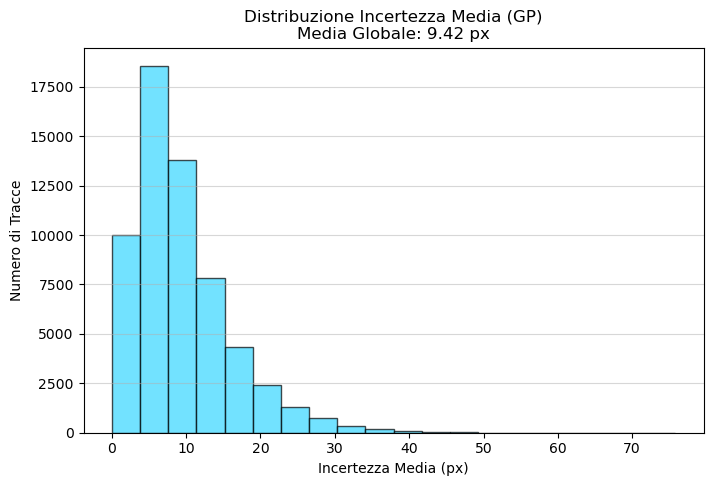

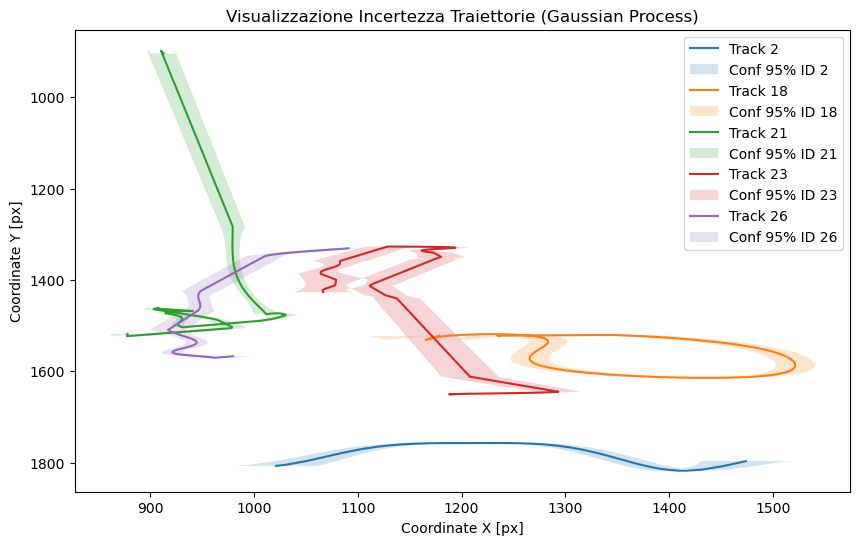

In [ ]:
# ==========================================
# 6. FEATURE EXTRACTION & UNCERTAINTY (QUANTIFICAZIONE)
# ==========================================

import warnings
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel
from sklearn.exceptions import ConvergenceWarning

def compute_features(df_track, tid):
    """
    Calcola le feature cinematiche (velocità, accelerazione, curvatura) per una singola traccia.

    Args:
        df_track (pd.DataFrame): DataFrame contenente i dati di una singola traccia (t, x, y).
        tid (int): ID della traccia.

    Returns:
        pd.DataFrame: DataFrame arricchito con colonne vx, vy, speed, accel, curvature, path_length.
                      Ritorna None se la traccia è troppo breve (< 3 punti).
    """
    # Servono almeno 3 punti per calcolare derivate e curvatura
    if len(df_track) < 3: return None

    t, x, y = df_track['t'].values, df_track['x'].values, df_track['y'].values

    # 1. Calcolo Velocità (Derivata prima della posizione)
    # np.gradient usa differenze centrali per una stima più accurata
    vx = np.gradient(x, t)
    vy = np.gradient(y, t)
    speed = np.sqrt(vx**2 + vy**2) # Modulo della velocità

    # 2. Calcolo Accelerazione (Derivata prima della velocità)
    ax = np.gradient(vx, t)
    ay = np.gradient(vy, t)
    accel = np.sqrt(ax**2 + ay**2) # Modulo dell'accelerazione

    # 3. Calcolo Curvatura (Kappa)
    # Formula: k = |x'y'' - y'x''| / (x'^2 + y'^2)^(3/2)
    denom = (vx**2 + vy**2)**1.5

    # Gestione divisione per zero (es. ape ferma)
    with np.errstate(divide='ignore', invalid='ignore'):
        kappa = np.abs(vx*ay - vy*ax)/denom
        kappa = np.nan_to_num(kappa) # Sostituisce NaNs con 0

    # 4. Calcolo Lunghezza percorso cumulativa
    # Distanza euclidea tra punti successivi
    dists = np.sqrt(np.diff(x, prepend=x[0])**2 + np.diff(y, prepend=y[0])**2)
    path_len = np.cumsum(dists)

    return pd.DataFrame({
        'track_id': tid,
        't': t, 'x': x, 'y': y,
        'vx': vx, 'vy': vy,
        'speed': speed,
        'accel': accel,
        'curvature': kappa,
        'path_length': path_len
    })

def gp_uncertainty(t, coords):
    """
    Stima l'incertezza della traiettoria utilizzando un Gaussian Process Regressor.

    Args:
        t (array): Vettore dei tempi.
        coords (array): Vettore delle coordinate (X o Y).

    Returns:
        tuple: (prediction, sigma)
            - prediction: Coordinate "lisciate" dal modello.
            - sigma: Deviazione standard (incertezza) per ogni punto.
    """
    # --- BLOCCO SOPPRESSIONE WARNING ---
    # Ignoriamo i warning di convergenza per tracce molto brevi o perfettamente lineari
    warnings.filterwarnings("ignore", category=ConvergenceWarning)

    # Campionamento (Downsampling) per velocità se la traccia è lunghissima (>500 punti)
    if len(t) > 500:
        idx = np.linspace(0, len(t)-1, 500, dtype=int)
        t = t[idx]
        coords = coords[idx]

    X = t.reshape(-1, 1)

    # --- DEFINIZIONE KERNEL ROBUSTA ---
    # ConstantKernel: Scala l'ampiezza della funzione. Bounds ampi (1e-5, 1e5) per evitare warning.
    # RBF (Radial Basis Function): Gestisce la "fluidità" della curva.
    kernel = ConstantKernel(1.0, (1e-5, 1e5)) * RBF(length_scale=1.0, length_scale_bounds=(1e-5, 1e5))

    # --- REGRESSORE STABILIZZATO ---
    # alpha=0.1: Aggiunge un piccolo "jitter" (rumore) alla diagonale della matrice di covarianza.
    #            È CRUCIALE per la stabilità numerica e per evitare errori "ABNORMAL_TERMINATION_IN_LNSRCH".
    # n_restarts_optimizer=10: Tenta il fitting 10 volte partendo da iperparametri diversi per evitare minimi locali.
    gp = GaussianProcessRegressor(
        kernel=kernel,
        alpha=0.1,          # Valore aumentato per stabilità numerica
        normalize_y=True,
        n_restarts_optimizer=10
    )

    try:
        gp.fit(X, coords)
        # return_std=True restituisce la deviazione standard (sigma) che rappresenta l'incertezza
        prediction, sigma = gp.predict(X, return_std=True)
    except Exception:
        # Fallback di sicurezza: se il fitting fallisce matematicamente, restituisci incertezza zero
        return coords, np.zeros_like(coords)

    return prediction, sigma

# ==========================================
# ESECUZIONE ANALISI E PLOT
# ==========================================

# Liste per accumulare dati
all_features_list = []
uncertainty_stats = []

if all_tracks:
    print("\n[TASK 2 & 3] Calcolo features e QUANTIFICAZIONE incertezza...")
    track_ids = df_all['track_id'].unique()

    # Cartella output features
    features_dir = out_dir / "features"
    features_dir.mkdir(exist_ok=True)

    # --- CICLO SU OGNI TRACCIA ---
    for tid in track_ids:
        sub = df_all[df_all['track_id'] == tid].sort_values('t')

        # 1. Calcolo Feature Cinematiche
        feats = compute_features(sub, tid)
        if feats is not None:
            feats.to_csv(features_dir / f"feats_{tid}.csv", index=False)
            all_features_list.append(feats)

        # 2. Calcolo Quantitativo Incertezza (Solo se traccia sufficientemente lunga)
        if len(sub) >= 5:
            t, x, y = sub['t'].values, sub['x'].values, sub['y'].values

            # Otteniamo sigma (deviazione standard) per X e Y separatamente
            _, sigma_x = gp_uncertainty(t, x)
            _, sigma_y = gp_uncertainty(t, y)

            # Quantificazione: Combiniamo l'incertezza su X e Y
            # L'incertezza posizionale totale è la distanza euclidea delle deviazioni standard
            sigma_pos = np.sqrt(sigma_x**2 + sigma_y**2)

            avg_unc = np.mean(sigma_pos)
            max_unc = np.max(sigma_pos)

            uncertainty_stats.append({
                'track_id': tid,
                'avg_uncertainty_px': avg_unc,
                'max_uncertainty_px': max_unc
            })

    # --- SALVATAGGIO REPORT INCERTEZZA ---
    if uncertainty_stats:
        df_unc = pd.DataFrame(uncertainty_stats)
        unc_csv_path = out_dir / "uncertainty_quantification.csv"
        df_unc.to_csv(unc_csv_path, index=False)

        # Calcolo metriche globali
        global_avg_unc = df_unc['avg_uncertainty_px'].mean()
        print(f"\n[REPORT INCERTEZZA]")
        print(f"File salvato: {unc_csv_path}")
        print(f"Incertezza Media Globale: {global_avg_unc:.3f} px")

        # --- PLOT 1: ISTOGRAMMA INCERTEZZA (QUANTITATIVO) ---
        plt.figure(figsize=(8, 5))
        plt.hist(df_unc['avg_uncertainty_px'], bins=20, color='#36d7ff', edgecolor='black', alpha=0.7)
        plt.title(f"Distribuzione Incertezza Media (GP)\nMedia Globale: {global_avg_unc:.2f} px")
        plt.xlabel("Incertezza Media (px)")
        plt.ylabel("Numero di Tracce")
        plt.grid(axis='y', alpha=0.5)
        plt.savefig(out_dir / "uncertainty_histogram.png", dpi=150)
        print("Istogramma incertezza salvato.")
        plt.show()

    # --- PLOT 2: ESEMPIO VISIVO INCERTEZZA (QUALITATIVO) ---
    plt.figure(figsize=(10,6))
    count_plotted = 0
    for tid in track_ids:
        if count_plotted >= 5: break # Plottiamo solo i primi 5 ID per chiarezza
        sub = df_all[df_all['track_id'] == tid].sort_values('t')
        if len(sub) < 5: continue

        t, x, y = sub['t'].values, sub['x'].values, sub['y'].values
        mx, sigma_x = gp_uncertainty(t, x) # Ricalcoliamo per plottare
        my, sigma_y = gp_uncertainty(t, y)

        plt.plot(mx, my, label=f'Track {tid}')

        # Area colorata = Intervallo di confidenza al 95% (circa +/- 1.96 sigma)
        # Visualizza visivamente dove il modello è "incerto" sulla posizione dell'ape
        plt.fill_betweenx(my, mx - 1.96*sigma_x, mx + 1.96*sigma_x, alpha=0.2, label=f'Conf 95% ID {tid}')
        count_plotted += 1

    plt.legend()
    plt.gca().invert_yaxis() # Invertiamo Y (coordinate immagine)
    plt.xlabel("Coordinate X [px]")
    plt.ylabel("Coordinate Y [px]")
    plt.title("Visualizzazione Incertezza Traiettorie (Gaussian Process)")
    plt.savefig(out_dir / "uncertainty_visual_example.png", dpi=150)
    plt.show()

### COMMENTI

1. Interpretazione del Valore Numerico (9.419 px): il valore di circa 9.4 pixel rappresenta la deviazione standard media (l'errore posizionale) associata alle traiettorie stimate. Se contestualizziamo questo dato con le dimensioni delle api estratte precedentemente nel notebook (dove l'area minima impostata era di 300 px e l'area media si aggirava tra i 3500 e i 4500 px a seconda del video), un raggio di incertezza di soli 9.4 pixel per localizzare il centroide dell'insetto è estremamente basso e sintomo di un'alta precisione. Significa che, in media, il modello è molto sicuro della posizione in cui si trova l'ape fotogramma per fotogramma.

2. Le tracce con incertezza al di sotto o in linea con la media (es. < 9-10 px) sono quelle dove l'ape si è mossa fluidamente ed è stata tracciata senza interruzioni dal Filtro di Kalman. Sono i dati d'oro per l'analisi cinematica. I picchi di incertezza (la coda dell'istogramma) indicano esattamente i momenti e le tracce in cui il sistema è andato "in crisi". Come citato nel report, questi valori alti di incertezza emergono quando l'ape è parzialmente occlusa da un'altra ape (i famosi "agglomerati" citati nell'introduzione), si trova ai bordi dell'inquadratura, oppure fa un movimento altamente irregolare non previsto dal modello fisico a velocità costante, oppure quando l'addetto inserisce la mano nella teca.

3. Le linee continue rappresentano le coordinate $X$ e $Y$ delle api "lisciate" (smoothed) dal Gaussian Process Regressor. Non sono i punti grezzi catturati dal rilevatore fotogramma per fotogramma, ma la traiettoria ottimizzata matematicamente dal modello. Le bande sfumate colorate (Conf 95%) sono la parte più importante del grafico: il codice disegna un alone attorno alla traiettoria pari a $1.96$ x $\sigma$. Questo alone rappresenta l'intervallo di confidenza al 95%. In termini pratici, il modello ci sta dicendo: "Sono sicuro al 95% che in questo specifico istante l'ape si trovi all'interno di questa fascia colorata".
   - Tratti "sottili" (Bassa incertezza): Quando l'alone colorato è molto stretto e quasi coincide con la linea della traiettoria, significa che l'ape si stava muovendo in modo predicibile, senza occlusione, in un'area ben illuminata. Il modello ha un'altissima confidenza sulla sua posizione.
   - Tratti "larghi" o "gonfi" (Alta incertezza): Se in un certo punto della curva la banda sfumata si allarga improvvisamente, significa che in quel frangente il modello ha perso sicurezza. Visivamente, questo indica all'operatore che in quella zona spaziale l'ape potrebbe aver compiuto uno scatto anomalo, oppure si è scontrata/sovrapposta con un'altra ape, o ancora è passata sopra un riflesso sul fondo della scatola che ha disturbato la telecamera.

## VISUALIZZAZIONE STATISTICA AVANZATA: MEDIA E PERCENTILI

Questa sezione genera un grafico a barre raggruppate per visualizzare la stabilità della rilevazione nel tempo, superando i limiti di un semplice conteggio medio.

### 1. ROBUSTEZZA STATISTICA: Dal Massimo ai Percentili
Nonostante le ottimizzazioni al tracking, il conteggio puntuale delle api rimaneva soggetto a fluttuazioni (*outliers*) dovute a cambiamenti di luce o movimenti della vegetazione/fondo, che il rilevatore interpretava erroneamente come picchi di attività.

Inizialmente, l'analisi si basava sul valore massimo e sulla media. Tuttavia, il "Massimo Assoluto" si è rivelato una metrica inaffidabile in un contesto di Computer Vision reale. Per ottenere una stima demografica robusta, abbiamo introdotto l'analisi dei percentili sulla serie temporale dei track attivi per ogni frame:

* **95° Percentile (Barra Rossa):** Rappresenta il numero massimo di api "sicuro", tagliando via il 5% di picchi anomali dovuti a errori di rilevamento (falsi positivi).
* **5° Percentile (Barra Verde):** Rappresenta il "livello basale" o minimo stabile di api presenti, escludendo i momenti in cui il tracker potrebbe perdere temporaneamente i soggetti (falsi negativi).
* **Media (Barra Azzurra):** Fornisce il valore centrale di tendenza.



### 2. TRACCIABILITÀ DELL'ESPERIMENTO
Il titolo del grafico e il nome del file salvato (`stats_active_plot_...`) vengono generati dinamicamente includendo i parametri chiave (`MinHits`, `MaxAge`, `MinArea`). Questo permette di confrontare grafici generati con configurazioni diverse e capire immediatamente quali parametri hanno prodotto quel risultato.


Generazione grafico statistica track attivi per frame...
Grafico statistiche track salvato in: C:\Users\linac\dataset\stats_active_plot_pct05_95_framesAll_hits30_age120.png


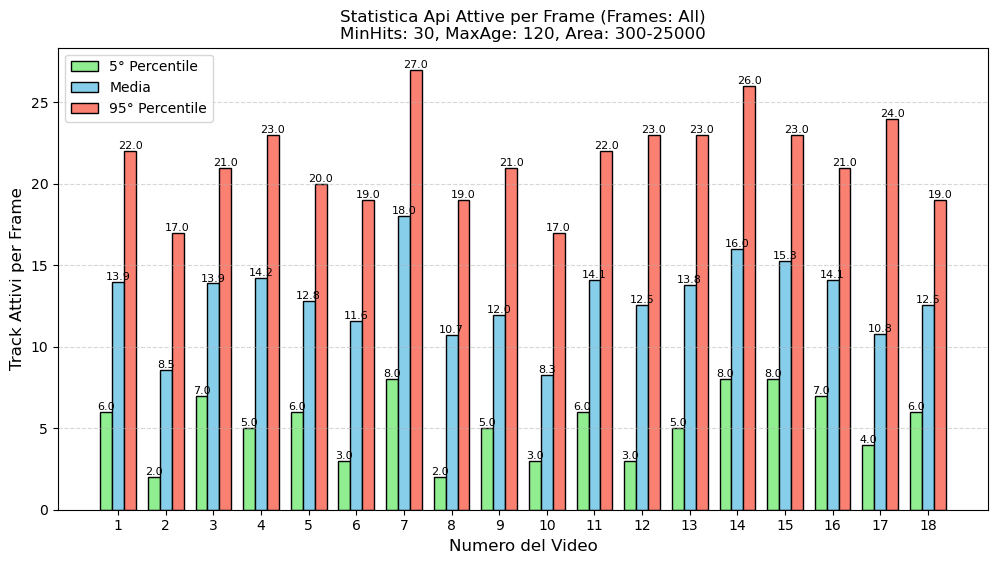

In [ ]:
# ==========================================
# 6bis. GENERAZIONE PLOT MEDIA E PERCENTILI (5° e 95°)
# ==========================================

if avg_counts:
    print("\nGenerazione grafico statistica track attivi per frame...")

    plt.figure(figsize=(12, 6))

    # Configurazione barre affiancate (3 barre per gruppo)
    x = np.arange(len(video_numbers))  # Posizioni etichette
    width = 0.25  # Larghezza delle barre (ridotta per farne stare 3)

    # Creazione delle tre serie di barre
    # Posizione: Sinistra (5%), Centro (Media), Destra (95%)
    rects1 = plt.bar(x - width, pct05_counts, width, label='5° Percentile', color='lightgreen', edgecolor='black')
    rects2 = plt.bar(x, avg_counts, width, label='Media', color='skyblue', edgecolor='black')
    rects3 = plt.bar(x + width, pct95_counts, width, label='95° Percentile', color='salmon', edgecolor='black')

    # Funzione per aggiungere etichette sopra le barre
    def autolabel(rects):
        for rect in rects:
            height = rect.get_height()
            plt.text(rect.get_x() + rect.get_width()/2., height,
                     f'{height:.1f}',
                     ha='center', va='bottom', fontsize=8)

    autolabel(rects1)
    autolabel(rects2)
    autolabel(rects3)

    plt.xlabel('Numero del Video', fontsize=12)
    plt.ylabel('Track Attivi per Frame', fontsize=12)
    plt.title('Confronto: 5° Pct vs Media vs 95° Pct (Track Attivi)', fontsize=14)
    plt.xticks(x, video_numbers)
    plt.legend()
    plt.grid(axis='y', linestyle='--', alpha=0.5)

    # --- DEFINIZIONE STRINGA FRAME ---
    if DEBUG_MODE:
        frames_info = f"{DEBUG_MAX_FRAMES}"
    else:
        frames_info = "All"

    # TITOLO DINAMICO COMPLETO
    plot_title = (f"Statistica Api Attive per Frame (Frames: {frames_info})\n"
                  f"MinHits: {GLOBAL_MIN_HITS}, MaxAge: {GLOBAL_MAX_AGE}, Area: {GLOBAL_MIN_AREA}-{GLOBAL_MAX_AREA}")
    plt.title(plot_title, fontsize=12)

    # NOME FILE DINAMICO
    plot_filename = f"stats_active_plot_pct05_95_frames{frames_info}_hits{GLOBAL_MIN_HITS}_age{GLOBAL_MAX_AGE}.png"
    save_path = out_dir / plot_filename

    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    print(f"Grafico statistiche track salvato in: {save_path}")

    plt.show()


### COMMENTI

Il valore medio per frame non rappresenta il "censimento totale" della scatola, ma quantifica i soggetti **chiaramente visibili e in movimento** in quel preciso istante. Che questo valore sia inferiore alla popolazione reale è un'ottima notizia per tre motivi fondamentali:

* **Coerenza Fisica e Biologica:** In un ambiente reale e tridimensionale, è fisicamente impossibile che il 100% delle api sia perfettamente isolato e visibile in ogni singolo millesimo di secondo. Le api si sovrappongono (*occlusioni*), formano agglomerati temporanei, oppure si fermano ai bordi dell'inquadratura mimetizzandosi con le pareti della scatola. Un calo fisiologico nel conteggio per frame è la naturale traduzione matematica di questi comportamenti.

* **Assenza di Falsi Positivi ("Dati Fantasma"):** Se la media (o peggio, il 95° percentile) superasse significativamente il numero reale di api, significherebbe che il sistema sta "allucinando" molti soggetti inesistenti. Questo accade quando il tracker scambia un riflesso sul vetro o un'ombra per un insetto, oppure quando "spezza" un'ape in due tracce distinte, magari a causa delle ali o delle zampe dell'ape. Avere una media inferiore al numero reale certifica che i filtri (come la `Min Area` o i parametri del *Background Subtractor*) stanno lavorando bene, escludendo il rumore di fondo.

* **Un Sistema Conservativo e Affidabile:** In ambito scientifico, è preferibile "perdere" un'ape per qualche frame (un falso negativo temporaneo, gestibile fluidamente dal *Filtro di Kalman*) piuttosto che generare traiettorie spurie di api inesistenti (*falsi positivi*). I dati estratti dal sistema sono intrinsecamente conservativi: l'algoritmo traccia solo ciò di cui è ragionevolmente sicuro.

## VISUALIZZAZIONE DELLO SPAZIO DELLE FEATURES (Analisi Cinematica)

Questa sezione genera una rappresentazione grafica delle relazioni cinematiche estratte, permettendo di identificare *cluster comportamentali* nel movimento delle api.

Vengono prodotti tre grafici distinti (Subplots):

1.  **Velocità vs. Accelerazione (Scatter Plot):**
    * Mette in relazione l'intensità del movimento con la sua variazione.
    * *Interpretazione:* Punti ad alta velocità e bassa accelerazione indicano volo di crociera stabile. Punti ad alta accelerazione indicano scatti improvvisi, partenze o reazioni a stimoli.

2.  **Velocità vs. Curvatura (Scatter Plot):**
    * Esplora la relazione tra rapidità e tortuosità della traiettoria.
    * *Ipotesi Etologica:* In natura esiste spesso una correlazione inversa:
        * **Volo Direzionale:** Alta velocità, Bassa curvatura (spostamento rapido da un punto all'altro).
        * **Volo Esplorativo/Interazione:** Bassa velocità, Alta curvatura (ricerca locale, hovering o interazione sociale).

3.  **Distribuzione Lunghezza Percorso (Istogramma):**
    * Analizza la persistenza delle tracce (distanza totale percorsa da ogni singola ape).
    * Ci permette di capire la natura del dataset: stiamo tracciando prevalentemente api "di passaggio" (tracce brevi) o api che risiedono a lungo nel campo visivo (tracce lunghe)?


Generazione plot Spazio delle Feature (Velocità, Accelerazione, Curvatura)...
Grafico Spazio Feature salvato in: C:\Users\linac\dataset\feature_space_plot_hits30_age120.png


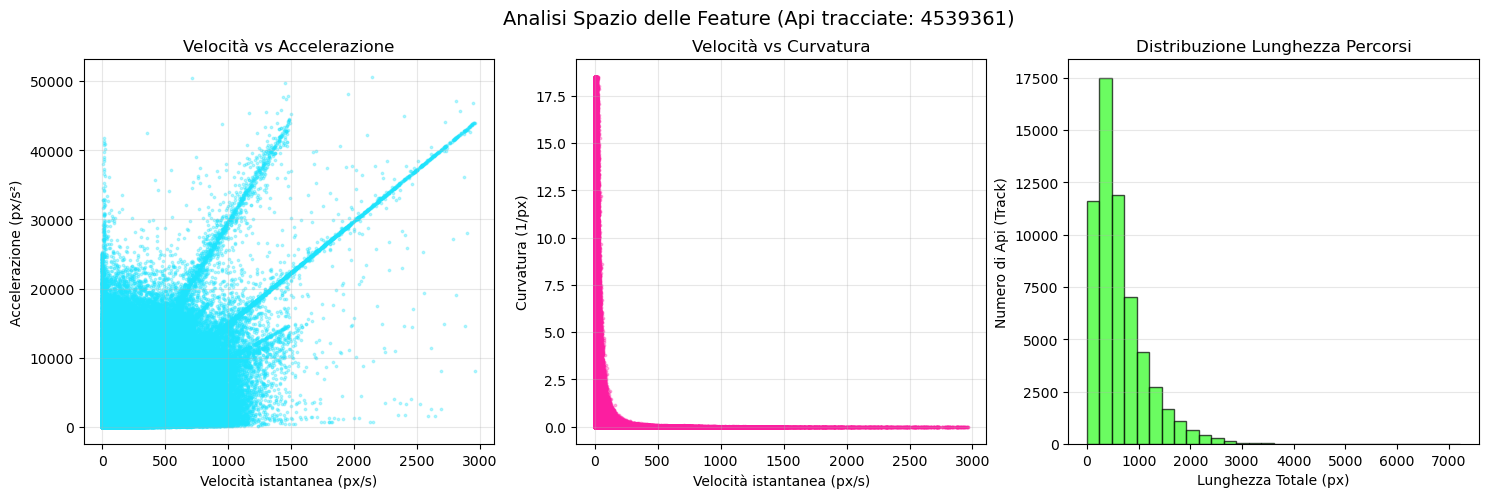

In [ ]:
# ==========================================
# 6ter. VISUALIZZAZIONE SPAZIO DELLE FEATURE
# ==========================================
# Richiesto: Rappresentare traiettorie considerando velocità, accelerazione, curvatura, lunghezza.

if all_features_list:
    print("\nGenerazione plot Spazio delle Feature (Velocità, Accelerazione, Curvatura)...")

    # 1. Aggregazione Dati
    # Uniamo tutte le features di tutte le api in un unico DataFrame gigante per l'analisi globale
    df_feats_all = pd.concat(all_features_list, ignore_index=True)

    # Creiamo una figura con 3 subplot affiancati
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # --- SUBPLOT 1: Velocità vs Accelerazione ---
    # Scatter plot: ogni punto è un istante di tempo di un'ape.
    # alpha=0.3: Trasparenza alta per gestire la sovrapposizione di migliaia di punti (heatmap effect)
    # s=3: Dimensione punti ridotta
    axes[0].scatter(df_feats_all['speed'], df_feats_all['accel'],
                    alpha=0.3, s=3, c='#1ee3fc', label='Frame data')
    axes[0].set_title("Velocità vs Accelerazione")
    axes[0].set_xlabel("Velocità istantanea (px/s)")
    axes[0].set_ylabel("Accelerazione (px/s²)")
    axes[0].grid(True, alpha=0.3)

    # --- SUBPLOT 2: Velocità vs Curvatura ---
    # La curvatura può avere picchi matematici enormi (se raggio -> 0).
    # Filtriamo il top 1% dei valori (outliers) per rendere il grafico leggibile.
    max_k = df_feats_all['curvature'].quantile(0.99)
    subset_k = df_feats_all[df_feats_all['curvature'] <= max_k]

    axes[1].scatter(subset_k['speed'], subset_k['curvature'],
                    alpha=0.3, s=3, c='#fc1ea0', label='Frame data')
    axes[1].set_title("Velocità vs Curvatura")
    axes[1].set_xlabel("Velocità istantanea (px/s)")
    axes[1].set_ylabel("Curvatura (1/px)")
    axes[1].grid(True, alpha=0.3)

    # --- SUBPLOT 3: Distribuzione Lunghezza Percorso ---
    # Qui non lavoriamo per frame, ma per traccia intera.
    # Prendiamo il valore massimo della 'path_length' cumulativa per ogni ID univoco.
    track_lengths = df_feats_all.groupby('track_id')['path_length'].max()

    axes[2].hist(track_lengths, bins=30, color='#2dfc1e', edgecolor='black', alpha=0.7)
    axes[2].set_title("Distribuzione Lunghezza Percorsi")
    axes[2].set_xlabel("Lunghezza Totale (px)")
    axes[2].set_ylabel("Numero di Api (Track)")
    axes[2].grid(axis='y', alpha=0.3)

    # Titolo globale della figura
    plt.suptitle(f"Analisi Spazio delle Feature (Punti totali analizzati: {len(df_feats_all)})", fontsize=14)

    # Salvataggio su file con parametri nel nome
    feat_plot_filename = f"feature_space_plot_hits{GLOBAL_MIN_HITS}_age{GLOBAL_MAX_AGE}.png"
    save_path_feat = out_dir / feat_plot_filename

    # bbox_inches='tight' evita che le etichette vengano tagliate nel PNG
    plt.savefig(save_path_feat, dpi=150, bbox_inches='tight')
    print(f"Grafico Spazio Feature salvato in: {save_path_feat}")

    plt.show()

### COMMENTI

### CORRELAZIONI CINEMATICHE



### 1. Velocità vs. Accelerazione

Questo scatter plot mette in relazione l'intensità del movimento con la sua variazione ne tempo.

* **Stato basale:** La densità elevatissima (il "cuore" del cluster) nell'area a bassa velocità e bassa accelerazione rappresenta l'attività ordinaria: esplorazione lenta dell'arena, interazioni o stazionaomento (*hovering*).

* **Voli direzionali:** Le alte accelerazioni si registrano in pattern ben definiti, delineando gli "scatti" improvvisi. L'assenza di punti sparsi caoticamente dimostra che il tracciamento è continuo e che il *Filtro di Kalman* ha lavorato in modo eccellente, smussando i micro-errori di localizzazione che altrimenti avrebbero generato picchi di accelerazione fisicamente possibili.

* **Strutture diagonali:** Suggeriscono che alcune fasi del movimento, come accelerazioni quasi costanti o transizioni regolari tra stati di volo, si ripetano con dinamiche simili nel tempo. Questo indica che il comportamento non è puramente casuale, ma organizzato in sequenze motorie ricorrenti. Tuttavia, la forma così marcata di queste linee è amplificata dal metodo di calcolo dell’accelerazione. Poiché l’accelerazione è stata ottenuta come derivata discreta (gradiente) della velocità, le due variabili non sono indipendenti: l’accelerazione dipende direttamente dalle variazioni della velocità tra frame consecutivi.



#### 2. Velocità vs. Curvatura

Dal punto di vista etologico, questo grafico svela la natura del volo dell'insetto mostrando una netta distribuzioe a forma di "L":

* **Bassa Velocità / Alta Curvatura:** Quando l'ape si muove lentamente, è in grado di compiere manovre strette, girare su se stessa o ispezionare minuziosamente un'area ristretta.

* **Alta Velocità / Bassa Curvatura:** Quando l'ape accelera per attraversare la scatola, la sua traiettoria diventa quasi perfettamente rettilinea.

* **Assenza di Rumore Impulsivo:** Il quadrante "Alta Velocità - Alta Curvatura" è vuoto. Fisicamente, un insetto non può compiere un'inversione a 'U' istantanea alla massima velocità senza violare le leggi dell'inerzia. L'assenza di punti in quest'area certifica la purezza dei dati ed esclude errori gravi di tracciamento (es. il tracker che scambia un'ape per un'altra ai lati opposti dell'arena).



#### 3. Distribuzione Lunghezza Percorso

A differenza dei primi due grafici (calcolati frame-per-frame), questo istogramma analizza l'intera estensione della tracca (`path_length` cumulativo).

* **Tracce brevi (Coda a sinistra):** Indicano api passate velocemente davanti alla telecamera o occlusioni quasi immediate.

* **Tracce lunghe (Coda a destra):** Rappresentano i "sopravvissuti", ovvero i soggetti tracciati ininterrottamente per distanze significative. Queste tracce lunghe e stabili costituiscono i dati "d'oro" per le analisi comportamentali quantitative.

## GENERAZIONE VIDEO OVERLAY: VALIDAZIONE QUALITATIVA

L'ultima fase del processo è la generazione di video con **overlay grafico**. Questa operazione non aggiunge nuovi dati numerici, ma è fondamentale per la **validazione visiva** dei risultati (*Sanity Check*).

### OVBIETTIVO
Sovrapponiamo le traiettorie calcolate (il modello matematico) al video originale (il dato grezzo). Questo ci permette di rispondere a domande critiche sulla qualità del tracciamento:

1.  **Precisione:** Il centro calcolato corrisponde al centro reale dell'insetto?
2.  **Continuità (Identity Consistency):** Quando due api si incrociano, i loro ID (e quindi i colori) rimangono coerenti o si scambiano (*ID Switch*)?
3.  **Robustezza:** Ci sono "fantasmi" (tracce senza ape) generati da riflessi, o api reali che vengono ignorate?



### DETTAGLI IMPLEMENTATIVI
* **Color Coding Deterministico:** Il colore di ogni traccia è generato proceduralmente basandosi sul suo `Track ID`. Questo garantisce che l'Ape #5 abbia sempre lo stesso colore in tutti i frame, facilitando il controllo visivo.
* **Visualizzazione:**
    * **Cerchio:** Rappresenta la posizione attuale ($x, y$) stimata dal filtro di Kalman.
    * **Polyline:** Disegna la scia storica del movimento, permettendo di apprezzare la fluidità della traiettoria e la direzione del moto.

In [ ]:
# ==========================================
# 7. GENERAZIONE VIDEO OVERLAY (Scie Brevi) - PER TUTTI I VIDEO
# ==========================================

# Eseguiamo solo se abbiamo tracce valide e video da processare
if all_tracks and len(videos_to_process) > 0:

    # --- PARAMETRI VISUALIZZAZIONE ---
    # Impostazioni grafiche per rendere il video leggibile
    radius = 3                # Raggio del cerchio che indica l'ape
    thickness = 3             # Spessore della linea della scia
    color_seed_multiplier = 37 # Moltiplicatore per generare colori diversi per ID vicini (es. ID 1 e ID 2)

    # Lunghezza della scia visiva (None = Scia infinita, disegna tutto il percorso dall'inizio)
    # Se il video è lungo, meglio mettere un numero (es. 50) per evitare scarabocchi illeggibili.
    TRAIL_LENGTH = None

    print("\n--- GENERAZIONE VIDEO OVERLAY PER TUTTI I VIDEO ---")

    # >>> CICLO PRINCIPALE: Itera su tutti i video analizzati <<<
    for vid_in in videos_to_process:

        # Estrai il nome base del file (es. "N-0,001(1).MOV" -> "N-0,001(1)")
        video_basename = os.path.splitext(os.path.basename(vid_in))[0]

        # Nome file output univoco: Include i parametri usati per generarlo
        # Questo è vitale per confrontare diversi tentativi di tuning
        output_filename = f"overlay_{video_basename}_hits{GLOBAL_MIN_HITS}_age{GLOBAL_MAX_AGE}_area{GLOBAL_MIN_AREA}-{GLOBAL_MAX_AREA}.mp4"
        vid_out = out_dir / output_filename

        print(f"Elaborazione overlay per: {os.path.basename(vid_in)}...")

        # 1. FILTRO DATI
        # Estraiamo dal calderone globale (df_all) solo le tracce che appartengono a QUESTO video
        data_vid = df_all[df_all['video'] == video_basename]

        # Se il filtro è vuoto (nessuna ape trovata in questo video), passiamo al prossimo
        if data_vid.empty:
            print(f"  [!] Nessuna traccia trovata per {video_basename}, salto generazione video.")
            continue

        # 2. PREPARAZIONE VIDEO WRITER
        cap = cv2.VideoCapture(str(vid_in))
        w, h = int(cap.get(3)), int(cap.get(4))
        fps_out = cap.get(cv2.CAP_PROP_FPS) or 30.0

        # Codec 'mp4v' è ampiamente compatibile. Inizializziamo il file di uscita.
        out_vid = cv2.VideoWriter(str(vid_out), cv2.VideoWriter_fourcc(*'mp4v'), fps_out, (w, h))

        # 3. INDICIZZAZIONE DATI (Ottimizzazione Performance)
        # Invece di cercare nel DataFrame a ogni frame (lento), pre-carichiamo tutto in un dizionario
        # Struttura: { frame_numero : [(id, x, y), (id, x, y)...] }
        frame_data = defaultdict(list)
        for row in data_vid.itertuples():
            frame_data[int(row.frame)].append((int(row.track_id), int(row.x), int(row.y)))

        # Struttura per ricordare la storia passata di ogni ID (per disegnare la scia)
        history = defaultdict(list)

        frame_idx = 0
        max_overlay_frames = DEBUG_MAX_FRAMES if DEBUG_MODE else None

        # 4. CICLO DI RENDERING FRAME-BY-FRAME
        while True:
            ret, frame = cap.read()
            if not ret: break

            # Se ci sono dati per questo frame corrente...
            if frame_idx in frame_data:
                current_points = frame_data[frame_idx]

                for (tid, x, y) in current_points:
                    # A. Aggiorna la storia della posizione per questo ID
                    history[tid].append((x, y))

                    # Se TRAIL_LENGTH è attivo, rimuovi i punti vecchi (effetto "serpente")
                    if TRAIL_LENGTH and len(history[tid]) > TRAIL_LENGTH:
                         history[tid].pop(0)

                    # B. Generazione Colore Deterministica
                    # Usiamo l'ID come seme casuale: L'ID 5 sarà sempre dello stesso colore, frame dopo frame
                    np.random.seed(tid)
                    color = (int((tid * color_seed_multiplier) % 255),
                             int((tid * 179) % 255),
                             int((tid * 89) % 255))

                    # C. Disegno Scia (Polylines)
                    if len(history[tid]) > 1:
                        pts = np.array(history[tid], np.int32)
                        pts = pts.reshape((-1, 1, 2))
                        # isClosed=False perché la scia è aperta
                        cv2.polylines(frame, [pts], isClosed=False, color=color, thickness=thickness)

                    # D. Disegno Posizione Attuale (Cerchio) e Label ID
                    cv2.circle(frame, (x, y), 6, color, -1) # -1 riempie il cerchio
                    cv2.putText(frame, f"ID {tid}", (x + 5, y - 5),
                                cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 1, cv2.LINE_AA)

            # Scrivi il frame modificato nel video di output
            out_vid.write(frame)

            frame_idx += 1
            if max_overlay_frames and frame_idx >= max_overlay_frames:
                break

        cap.release()
        out_vid.release()
        print(f"  -> Salvato: {output_filename}")

    print("\nGenerazione overlay completata per tutti i video.")


--- GENERAZIONE VIDEO OVERLAY PER TUTTI I VIDEO ---
Elaborazione overlay per: N-0,001(1).MOV...
  -> Salvato: overlay_N-0,001(1)_hits30_age120_area300-25000.mp4
Elaborazione overlay per: N-0,001(2).MOV...
  -> Salvato: overlay_N-0,001(2)_hits30_age120_area300-25000.mp4
Elaborazione overlay per: N-0,001(3).MOV...
  -> Salvato: overlay_N-0,001(3)_hits30_age120_area300-25000.mp4
Elaborazione overlay per: N-0,01(1).MOV...
  -> Salvato: overlay_N-0,01(1)_hits30_age120_area300-25000.mp4
Elaborazione overlay per: N-0,01(2).MOV...
  -> Salvato: overlay_N-0,01(2)_hits30_age120_area300-25000.mp4
Elaborazione overlay per: N-0,01(3).MOV...
  -> Salvato: overlay_N-0,01(3)_hits30_age120_area300-25000.mp4
Elaborazione overlay per: N-0,1 (1).MOV...
  -> Salvato: overlay_N-0,1 (1)_hits30_age120_area300-25000.mp4
Elaborazione overlay per: N-0,1 (2).MOV...
  -> Salvato: overlay_N-0,1 (2)_hits30_age120_area300-25000.mp4
Elaborazione overlay per: N-0,1 (3).MOV...
  -> Salvato: overlay_N-0,1 (3)_hits30_age

## CONCLUSIONI

Il lavoro svolto ha permesso di trasformare un codice di base per il rilevamento oggetti in un sistema completo per l'analisi etologica automatizzata. Le principali conquiste del progetto sono state:
- La comprensione profonda di come i parametri di Computer Vision (Min/Max Area, Max Age) influenzano la lettura biologica del dato.
- La risoluzione del problema della sovrastima delle popolazioni attraverso l'adozione di metriche statistiche robuste (percentili) anziché cumulative.
- La validazione biomeccanica del modello tramite l'analisi dello spazio delle feature, che ha confermato la coerenza fisica delle traiettorie estratte.

L'adozione dei Processi Gaussiani ha permesso inoltre di assegnare un valore numerico di affidabilità a ciascuna traccia, fornendo una base solida per eventuali studi successivi basati su questi dati. Futuri sviluppi potrebbero servire per gestire le occlusioni complesse, permettendo di distinguere e tracciare le api anche quando si trovano all'interno di agglomerati densi.